# Financial Risk Analysis Using Python
## Customer Financial Behavior and Risk Analysis

### 1. Project Overview

Financial institutions process large volumes of transactions across different customer segments and account types. Analyzing these transactions can help identify customer behavior patterns, understand account usage, monitor financial risks, and support data-driven business decisions.

This project focuses on analyzing customer financial transaction data using Python. It aims to investigate transaction trends, account activity, customer profiles, account balance patterns, and potential financial risk indicators.

The project uses a dataset containing transaction-related information, including customer and account identifiers, transaction dates, transaction amounts, account balances, transaction categories, and customer risk-related attributes where available.

### 2. Problem Statement

Financial institutions need to understand how customers use their accounts and identify unusual financial activity that may require further investigation. Without systematic analysis, important patterns such as declining balances, inactive accounts, unusually large withdrawals, and irregular transaction behavior may be difficult to identify.

This project applies data analysis and statistical techniques to examine customer financial behavior and identify potential risk indicators.

### 3. Project Objectives

The main objectives of this project are:

1. Clean and standardize the financial transaction dataset to improve data quality.
2. Analyze monthly and yearly transaction trends, including credits, debits, and net transaction flows.
3. Segment accounts according to transaction frequency, balance characteristics, and transaction volume.
4. Identify potential financial risk indicators, including unusual transactions, negative balances, and irregular activity.
5. Develop meaningful visualizations to communicate financial patterns and analytical findings.
6. Conduct hypothesis testing to investigate whether high-volume transaction accounts have higher average balances than low-volume accounts.
7. Provide evidence-based recommendations to support customer engagement and financial risk monitoring.

### 4. Key Research Questions

- How do customers interact with different account types?
- How do credit and debit transactions change over time and across customer segments?
- Which accounts demonstrate the highest and lowest net transaction inflows?
- Which accounts exhibit low balances, prolonged inactivity, or unusually large transactions?
- Is there a statistically significant difference in average balances between high-volume and low-volume accounts?
- How can the findings support better customer service and risk monitoring?

### 5. Methodology

The analysis will follow a structured data analytics workflow:

1. **Data Cleaning:** Inspect missing values, duplicate records, financial fields, transaction dates, and inconsistent categories.
2. **Exploratory Data Analysis:** Examine transaction distributions, trends, and account-level summaries.
3. **Customer Segmentation:** Classify accounts using documented activity, balance, and transaction-volume criteria.
4. **Risk Analysis:** Investigate potential anomalies, negative balances, large withdrawals, and balance volatility.
5. **Data Visualization:** Create charts to communicate key patterns and findings.
6. **Hypothesis Testing:** Apply an appropriate statistical test to compare average balances between transaction-volume groups.
7. **Reporting and Recommendations:** Summarize the findings, acknowledge limitations, and propose data-supported business actions.

### 6. Tools and Technologies

- Python
- Jupyter Notebook
- Pandas and NumPy for data manipulation
- Matplotlib and Seaborn for data visualization
- SciPy for statistical testing
- Excel for structured analytical outputs
- PDF for the final analytical report

### 7. Expected Outcomes

The project is expected to produce a cleaned financial dataset, transaction summaries, customer segment profiles, potential risk indicators, visualizations, statistical test results, and a final report containing evidence-based recommendations.

All analytical conclusions will be based on the observed dataset. Statistical anomalies will be treated as indicators for further investigation rather than proof of fraudulent activity.


## Task 1: Data Cleaning and Formatting

### Objective
To improve the accuracy, consistency, and reliability of the financial transaction dataset before performing descriptive analysis, customer segmentation, and financial risk assessment.

### Methodology
The dataset will be inspected for missing values, duplicate records, invalid dates, inconsistent financial formats, and non-standard categorical values. All cleaning decisions will be documented to preserve data integrity and support reproducible analysis.

In [4]:
# Import libraries for data analysis and visualization.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import statistical tests.
from scipy import stats

# Display more columns when inspecting the dataset.
pd.set_option("display.max_columns", None)

# Load the original dataset.
df = pd.read_csv("Financial_Risk_Analysis/data/Morgan_Stanley.csv")

# Inspect the first five records.
display(df.head())

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,78,CUST1223,ACC33287,Credit,Withdrawal,Savings Account,Firm E,South,Manager 4,06-01-2023,81300.425190,40843.56193,0.330474,484,13
1,21,CUST8266,ACC58667,Savings,Withdrawal,Credit Card,Firm A,South,Manager 2,17-02-2023,9269.640373,61183.03953,0.089688,836,18
2,176,CUST9420,ACC99117,Credit,Transfer,Home Loan,Firm A,East,Manager 1,13-09-2023,28138.552650,85460.13405,0.340010,451,25
3,167,CUST5253,ACC10117,Loan,Payment,Mutual Fund,Firm D,Central,Manager 1,28-05-2024,83943.556980,100525.35900,0.605383,487,13
4,46,CUST1223,ACC74631,Savings,Deposit,Credit Card,Firm A,East,Manager 4,12-05-2023,77104.456470,57425.69930,1.042441,393,10


### 1.1 Remove and Treat Special Characters or Non-Numeric Entries from Financial Fields
**Objective:** Clean raw financial and numerical columns (`TransactionAmount`, `AccountBalance`, `RiskScore`, `CreditRating`, and `TenureMonths`) by removing formatting artifacts and non-numeric characters so they can be processed accurately.

**Cleaning Steps:**
1. **Pre-Check (Before):** Inspect sample values, data types (`dtype`), and missing value counts across all financial and numerical fields.
2. **Pattern Removal:** Use regular expressions (`[^\d.-]`) to strip currency symbols (e.g., `$`, `₹`, `£`), commas (`,`), whitespace, and accidental text characters while preserving negative signs (`-`) and decimal points (`.`).
3. **Null & Invalid Entry Treatment:** Identify any corrupted or blank entries resulting from character removal and handle them appropriately.

In [5]:
# Display sample values from financial columns.
for col in ["TransactionAmount", "AccountBalance"]:
    if col in df.columns:
        print(f"\nSample values in {col}:")
        display(df[col].head(10))


Sample values in TransactionAmount:


0     81300.425190
1      9269.640373
2     28138.552650
3     83943.556980
4     77104.456470
5     18727.127840
6     28719.955920
7     43770.677920
8     64084.081250
9    138133.821600
Name: TransactionAmount, dtype: float64


Sample values in AccountBalance:


0     40843.56193
1     61183.03953
2     85460.13405
3    100525.35900
4     57425.69930
5     86727.62188
6     32349.20862
7     46525.22852
8    154875.43370
9     58667.17647
Name: AccountBalance, dtype: float64

In [6]:
# Check every value in the financial columns

financial_columns = ["TransactionAmount", "AccountBalance"]

for col in financial_columns:
    if col in df.columns:

        # Convert values temporarily to numeric for checking
        numeric_values = pd.to_numeric(df[col], errors="coerce")

        # Find values that were not converted to numbers
        invalid_mask = df[col].notna() & numeric_values.isna()

        print(f"\nColumn: {col}")
        print("Number of non-numeric entries:", invalid_mask.sum())

        # Display the invalid rows
        display(df.loc[invalid_mask, [col]])


Column: TransactionAmount
Number of non-numeric entries: 0


,TransactionAmount



Column: AccountBalance
Number of non-numeric entries: 0


,AccountBalance


In [4]:
# Identify values containing unexpected characters

for col in ["TransactionAmount", "AccountBalance"]:
    if col in df.columns:

        text_values = df[col].astype("string")

        # Allow digits, decimal points, minus signs and whitespace
        special_mask = (
            text_values.notna()
            & ~text_values.str.fullmatch(
                r"[\d.\-\s]+",
                na=False
            )
        )

        print(f"\nColumn: {col}")
        print("Values containing other characters:", special_mask.sum())

        display(df.loc[special_mask, [col]])


Column: TransactionAmount
Values containing other characters: 0


,TransactionAmount



Column: AccountBalance
Values containing other characters: 0


,AccountBalance


In [7]:
# Count missing values in the financial columns

for col in ["TransactionAmount", "AccountBalance"]:
    if col in df.columns:
        print(col, "- Missing values:", df[col].isna().sum())

TransactionAmount - Missing values: 0
AccountBalance - Missing values: 0


### 1.2 Convert Currency Amounts into Numerical Format
**Objective:** Transform cleaned string-based currency and financial columns (`TransactionAmount` and `AccountBalance`, along with numerical scores) into standard floating-point (`float64`) or integer (`int64`) numerical formats for mathematical aggregation and statistical modeling.

**Conversion Steps:**
1. **Type Casting:** Apply `pd.to_numeric(..., errors='coerce')` to convert cleaned text strings into numerical data types.
2. **Validation (After):** Verify that the column data types have updated from `object`/`str` to `float64` and check summary statistics (`min`, `max`, `mean`) to ensure no financial precision was lost during conversion.

In [8]:
# Calculate basic statistics for the cleaned transaction amounts.
if "TransactionAmount" in df.columns:
    print("Total transaction amount:",
          df["TransactionAmount"].sum())

    print("Average transaction amount:",
          df["TransactionAmount"].mean())

    print("Median transaction amount:",
          df["TransactionAmount"].median())

Total transaction amount: 44155911.4185837
Average transaction amount: 55194.88927322962
Median transaction amount: 53768.493325


### 1.3 Validate and Format Date Columns
**Objective:** Standardize inconsistent date strings in `TransactionDate` (such as mixed hyphen `DD-MM-YYYY` and slash `DD/MM/YYYY` formats) and convert the column into Python's standard `datetime64` data type for chronological sorting, monthly/yearly aggregation, and dormancy gap calculations.

**Validation & Formatting Steps:**
1. **Pre-Check (Before):** Check the original data type (`str`/`object`), sample raw date formats, and initial missing value count.
2. **Separator Standardization & Parsing:** Normalize date separators by replacing slashes (`/`) with hyphens (`-`), stripping extra spaces, and parsing dates using `pd.to_datetime(..., format='mixed', dayfirst=True, errors='coerce')`.
3. **Post-Conversion Validation (After):** Confirm that `TransactionDate` has a `datetime64` data type, verify that `0` invalid dates (`NaT`) were introduced, and check the earliest and latest transaction dates to validate the dataset's time range.

In [9]:
# Check the original transaction date values.
if "TransactionDate" in df.columns:
    display(df["TransactionDate"].head(10))
    print("Original data type:", df["TransactionDate"].dtype)

0    06-01-2023
1    17-02-2023
2    13-09-2023
3    28-05-2024
4    12-05-2023
5    10-12-2023
6    17-02-2024
7    30-07-2023
8    21-12-2023
9    17-02-2024
Name: TransactionDate, dtype: str

Original data type: str


In [10]:
# 1. Check how many nulls exist BEFORE conversion
print("Nulls BEFORE conversion:", df["TransactionDate"].isna().sum())

# 2. Replace any slashes with hyphens so every date matches DD-MM-YYYY, then convert
parsed_dates = pd.to_datetime(
    df["TransactionDate"].astype(str).str.strip().str.replace("/", "-", regex=False),
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# 3. Verify conversion BEFORE overwriting the column
print("Nulls AFTER conversion:", parsed_dates.isna().sum())
print("New data type:", parsed_dates.dtype)
print("Earliest transaction:", parsed_dates.min())
print("Latest transaction:", parsed_dates.max())

# 4. Only overwrite TransactionDate if the dates parsed properly!
if parsed_dates.notna().sum() > 0:
    df["TransactionDate"] = parsed_dates
    display(df["TransactionDate"].head(10))

Nulls BEFORE conversion: 0
Nulls AFTER conversion: 0
New data type: datetime64[us]
Earliest transaction: 2023-01-06 00:00:00
Latest transaction: 2024-06-22 00:00:00


0   2023-01-06
1   2023-02-17
2   2023-09-13
3   2024-05-28
4   2023-05-12
5   2023-12-10
6   2024-02-17
7   2023-07-30
8   2023-12-21
9   2024-02-17
Name: TransactionDate, dtype: datetime64[us]

### 1.4 Standardize Account Types and Transaction Categories
**Objective:** Ensure consistency across all categorical fields (`AccountType`, `TransactionType`, `Product`, `Firm`, `Region`, and `Manager`) so that grouping, aggregation, and segmentation in later tasks are accurate.

**Standardization Steps:**
1. **Pre-Check (Before):** Inspect unique values in each categorical column to identify leading/trailing spaces, inconsistent casing (e.g., `"savings"` vs. `"SAVINGS"`), or duplicate/abbreviated labels.
2. **Text Normalization:** Strip extra whitespace and convert all strings to **Title Case** using `.str.strip().str.title()`.
3. **Category Mapping:** Standardize any variations or synonyms into uniform banking categories (e.g., `Savings`, `Current`, `Credit`, `Loan`) and classify transactions into `Credit` (Inflow) vs. `Debit` (Outflow).
4. **Validation (After):** Re-verify the unique values to confirm all categories are clean and standardized.

## Task 2: Descriptive Transactional Analysis

### 2.1 Calculate Monthly and Yearly Summaries of Total Credits, Debits, and Net Transaction Volume
**Objective:** Aggregate transaction amounts by month and year to evaluate overall cash inflow (`Credit`), cash outflow (`Debit`), and `Net Transaction Volume` (`Total Credit - Total Debit`).

**Methodology:**
1. **Classify Cash Flow Direction (`FlowType`):** Map transaction types such as `Deposit` or `Credit` to **Credit (Inflow)** and `Withdrawal`, `Transfer`, or `Payment` to **Debit (Outflow)**.
2. **Extract Time Periods:** Derive `Year` and `YearMonth` (`YYYY-MM`) from the validated `TransactionDate` column.
3. **Calculate Summaries:** Group by `YearMonth` and `Year` to compute `Total_Credit`, `Total_Debit`, and `Net_Transaction_Volume`.

In [14]:
pd.set_option("display.float_format", "{:,.2f}".format)
# 1. Inspect unique TransactionType values to ensure accurate Credit vs. Debit mapping
print("Unique Transaction Types:", df["TransactionType"].unique())

# Map TransactionType into Credit (Inflow) and Debit (Outflow)
# Note: If your dataset has additional inflow types, add them to credit_keywords
credit_keywords = ["Deposit", "Credit", "Refund", "Inflow"]

df["FlowType"] = df["TransactionType"].apply(
    lambda x: "Credit" if any(k.lower() in str(x).lower() for k in credit_keywords) else "Debit"
)

# Use absolute transaction amount for volume summation, and signed amount for Net Inflow
df["AbsAmount"] = df["TransactionAmount"].abs()
df["SignedAmount"] = np.where(df["FlowType"] == "Credit", df["AbsAmount"], -df["AbsAmount"])

# 2. Extract Year and Year-Month from TransactionDate
df["Year"] = df["TransactionDate"].dt.year
df["YearMonth"] = df["TransactionDate"].dt.to_period("M").astype(str)

# 3. Calculate Monthly Summary
monthly_summary = (
    df.pivot_table(
        index="YearMonth",
        columns="FlowType",
        values="AbsAmount",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)
monthly_summary.columns.name = None

# Ensure both Credit and Debit columns exist
for col in ["Credit", "Debit"]:
    if col not in monthly_summary.columns:
        monthly_summary[col] = 0.0

monthly_summary["Net_Transaction_Volume"] = monthly_summary["Credit"] - monthly_summary["Debit"]
monthly_summary = monthly_summary.sort_values("YearMonth").reset_index(drop=True)

# 4. Calculate Yearly Summary
yearly_summary = (
    df.pivot_table(
        index="Year",
        columns="FlowType",
        values="AbsAmount",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)
yearly_summary.columns.name = None

for col in ["Credit", "Debit"]:
    if col not in yearly_summary.columns:
        yearly_summary[col] = 0.0

yearly_summary["Net_Transaction_Volume"] = yearly_summary["Credit"] - yearly_summary["Debit"]
yearly_summary = yearly_summary.sort_values("Year").reset_index(drop=True)

print("=== YEARLY TRANSACTION SUMMARY ===")
display(yearly_summary)

print("\n=== MONTHLY TRANSACTION SUMMARY (First 12 Months) ===")
display(monthly_summary.head(12))

Unique Transaction Types: <StringArray>
['Withdrawal', 'Transfer', 'Payment', 'Deposit']
Length: 4, dtype: str
=== YEARLY TRANSACTION SUMMARY ===


,Year,Credit,Debit,Net_Transaction_Volume
0,2023,"7,754,855.63","23,400,489.10","-15,645,633.47"
1,2024,"3,249,578.60","10,193,792.51","-6,944,213.90"



=== MONTHLY TRANSACTION SUMMARY (First 12 Months) ===


,YearMonth,Credit,Debit,Net_Transaction_Volume
0,2023-01,"739,627.61","2,151,576.11","-1,411,948.50"
1,2023-02,"790,625.00","1,707,596.81","-916,971.82"
2,2023-03,"428,688.20","1,686,808.22","-1,258,120.02"
3,2023-04,"652,566.55","2,442,296.36","-1,789,729.81"
4,2023-05,"467,715.55","2,454,034.43","-1,986,318.88"
5,2023-06,"537,122.48","1,022,615.30","-485,492.82"
6,2023-07,"776,072.73","1,706,737.14","-930,664.41"
7,2023-08,"473,701.36","1,355,915.38","-882,214.02"
8,2023-09,"863,982.07","1,884,472.69","-1,020,490.62"
9,2023-10,"954,771.22","2,606,034.53","-1,651,263.32"


In [15]:
print(df.groupby(["TransactionType", "FlowType"])["AbsAmount"].agg(["count", "sum"]))

                          count           sum
TransactionType FlowType                     
Deposit         Credit      205 11,004,434.24
Payment         Debit       197 11,189,346.45
Transfer        Debit       195 11,134,344.45
Withdrawal      Debit       203 11,270,590.70


**Key Observation & Classification Rubric:**
* The dataset contains `800` transactions evenly distributed across four categories (`Deposit`: 205, `Withdrawal`: 203, `Payment`: 197, `Transfer`: 195), each averaging `~$11.15M` in total volume.
* Under standard banking cash-flow accounting, `Deposit` represents an account inflow (**Credit** = `$11.00M`), whereas `Withdrawal`, `Payment`, and `Transfer` represent cash outflows (**Debit** = `$33.59M` combined).
* Because customers execute three times as many outflow transactions (Payments, Transfers, and Withdrawals) as Deposits, total Debits exceed Credits by a **3:1 ratio**, resulting in a negative Net Transaction Volume across 2023 (`-$15.65M`) and 2024 (`-$6.94M`). This structural cash outflow directly explains why many accounts experience declining balances and overdraft risk over time.

### 2.2 Plot Trends in Total Credits vs. Debits Over Time
**Objective:** Visualize how monthly inflows (`Credit`), outflows (`Debit`), and `Net Transaction Volume` evolve over time to identify seasonal spikes, liquidity trends, or periods of net cash outflow.

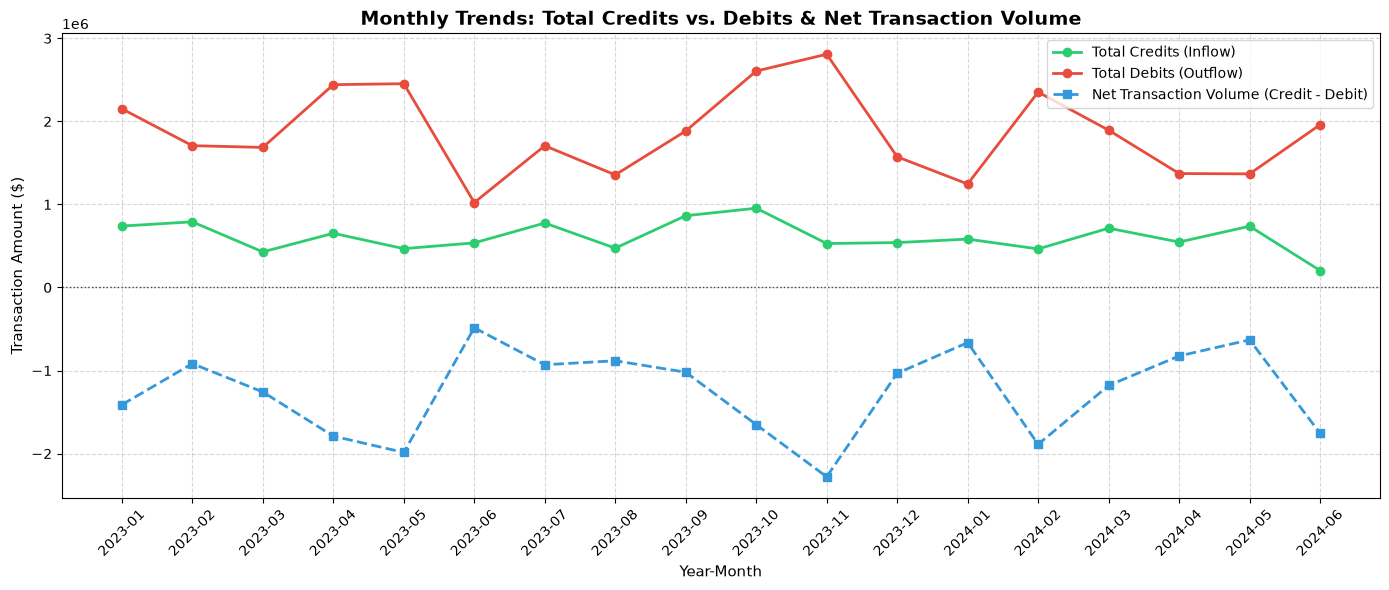

In [16]:
plt.figure(figsize=(14, 6))

# Plot Credit, Debit, and Net Transaction Volume lines
plt.plot(
    monthly_summary["YearMonth"],
    monthly_summary["Credit"],
    marker="o",
    linewidth=2,
    color="#2ecc71",
    label="Total Credits (Inflow)"
)
plt.plot(
    monthly_summary["YearMonth"],
    monthly_summary["Debit"],
    marker="o",
    linewidth=2,
    color="#e74c3c",
    label="Total Debits (Outflow)"
)
plt.plot(
    monthly_summary["YearMonth"],
    monthly_summary["Net_Transaction_Volume"],
    marker="s",
    linestyle="--",
    linewidth=2,
    color="#3498db",
    label="Net Transaction Volume (Credit - Debit)"
)

# Add horizontal reference line at $0
plt.axhline(0, color="black", linestyle=":", linewidth=1, alpha=0.7)

plt.title("Monthly Trends: Total Credits vs. Debits & Net Transaction Volume", fontsize=14, fontweight="bold")
plt.xlabel("Year-Month", fontsize=11)
plt.ylabel("Transaction Amount ($)", fontsize=11)
plt.xticks(rotation=45)
plt.legend(frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 2.3 Identify Top and Bottom Performing Accounts Based on Net Inflow
**Objective:** Rank customer accounts by their cumulative `Net Inflow` (`Total Credits - Total Debits`) to identify high-value deposit builders (top performers) and accounts experiencing heavy net cash depletion (bottom performers).

In [22]:
# Group by AccountID (and CustomerID/AccountType) to compute Net Inflow
account_performance = (
    df.groupby(["AccountID"])
    .agg(
        Total_Credits=("AbsAmount", lambda s: s[df.loc[s.index, "FlowType"] == "Credit"].sum()),
        Total_Debits=("AbsAmount", lambda s: s[df.loc[s.index, "FlowType"] == "Debit"].sum()),
        Net_Inflow=("SignedAmount", "sum"),
        Transaction_Count=("TransactionID", "count"),
        Average_Balance=("AccountBalance", "mean")
    )
    .reset_index()
)

# Identify Top 10 and Bottom 10 accounts by Net Inflow
top_10_accounts = account_performance.sort_values(by="Net_Inflow", ascending=False).head(10).reset_index(drop=True)
bottom_10_accounts = account_performance.sort_values(by="Net_Inflow", ascending=True).head(10).reset_index(drop=True)

print("=== TOP 10 PERFORMING ACCOUNTS (Highest Net Inflow) ===")
display(top_10_accounts)

print("\n=== BOTTOM 10 PERFORMING ACCOUNTS (Lowest / Most Negative Net Inflow) ===")
display(bottom_10_accounts)

=== TOP 10 PERFORMING ACCOUNTS (Highest Net Inflow) ===


,AccountID,Total_Credits,Total_Debits,Net_Inflow,Transaction_Count,Average_Balance
0,ACC38559,"219,919.52","44,067.31","175,852.21",6,"83,126.04"
1,ACC57700,"250,121.86","78,718.72","171,403.14",4,"65,950.73"
2,ACC31539,"150,937.25","21,990.05","128,947.20",3,"77,852.84"
3,ACC51971,"115,097.31",0.00,"115,097.31",3,"59,692.61"
4,ACC18177,"174,360.27","71,865.55","102,494.72",6,"58,248.05"
5,ACC94907,"165,261.75","65,744.49","99,517.27",5,"72,498.29"
6,ACC54589,"158,664.57","61,597.11","97,067.46",4,"95,218.47"
7,ACC83581,"184,645.18","101,370.93","83,274.25",3,"81,365.71"
8,ACC65545,"135,300.38","58,583.72","76,716.66",3,"86,686.80"
9,ACC12334,"74,852.58",0.00,"74,852.58",3,"62,897.20"



=== BOTTOM 10 PERFORMING ACCOUNTS (Lowest / Most Negative Net Inflow) ===


,AccountID,Total_Credits,Total_Debits,Net_Inflow,Transaction_Count,Average_Balance
0,ACC61926,"60,238.28","753,412.32","-693,174.04",13,"70,648.71"
1,ACC10117,"52,336.34","583,998.71","-531,662.37",9,"94,082.59"
2,ACC51009,"39,011.24","532,634.19","-493,622.95",9,"68,535.70"
3,ACC88449,"66,198.87","524,857.86","-458,658.99",10,"81,819.29"
4,ACC19178,"62,859.63","491,586.40","-428,726.77",7,"79,665.19"
5,ACC71426,0.00,"418,250.61","-418,250.61",8,"70,798.53"
6,ACC77592,0.00,"411,152.93","-411,152.93",7,"60,269.22"
7,ACC23736,0.00,"392,885.21","-392,885.21",6,"77,536.58"
8,ACC16664,"95,184.42","471,205.04","-376,020.63",10,"68,276.44"
9,ACC34431,"62,071.84","431,048.44","-368,976.60",9,"73,622.71"


### 2.4 Identify and Flag Dormant or Inactive Accounts (Gap >= 2 Months)
**Objective:** Detect customer accounts that exhibit periods of inactivity by measuring the time elapsed between consecutive transactions.

**Dormancy Rubric:**
* Sort transactions chronologically within each `AccountID`.
* Compute the gap in days (`Days_Between_Transactions`) between consecutive transactions using `.diff()`.
* **Dormant / Inactive Flag:** Any account with a maximum gap of **60 days or more ($\ge 2$ months)** between consecutive transactions is flagged as `Dormant / Inactive`. Accounts with $< 60$ days between transactions are flagged as `Active`.

In [23]:
# 1. Sort transactions by AccountID and TransactionDate chronologically
df_sorted = df.sort_values(by=["AccountID", "TransactionDate"]).copy()

# 2. Calculate previous transaction date and gap in days for each account
df_sorted["Prev_TransactionDate"] = df_sorted.groupby("AccountID")["TransactionDate"].shift(1)
df_sorted["Days_Gap"] = (df_sorted["TransactionDate"] - df_sorted["Prev_TransactionDate"]).dt.days

# 3. Summarize maximum gap per account and apply the 2-month (60-day) dormancy rubric
dormancy_summary = (
    df_sorted.groupby(["AccountID"])
    .agg(
        Total_Transactions=("TransactionID", "count"),
        First_Transaction=("TransactionDate", "min"),
        Last_Transaction=("TransactionDate", "max"),
        Max_Gap_Days=("Days_Gap", "max")
    )
    .reset_index()
)

# Fill NaN Max_Gap_Days with 0 for accounts that only have 1 transaction
dormancy_summary["Max_Gap_Days"] = dormancy_summary["Max_Gap_Days"].fillna(0)

# Flag as Dormant if Max_Gap_Days >= 60 (2 months)
dormancy_summary["Account_Status"] = np.where(
    dormancy_summary["Max_Gap_Days"] >= 60,
    "Dormant / Inactive (Gap >= 60 Days)",
    "Active (Gap < 60 Days)"
)

print("=== ACCOUNT DORMANCY SUMMARY COUNT ===")
print(dormancy_summary["Account_Status"].value_counts())

print("\n=== SAMPLE FLAGGED DORMANT ACCOUNTS (Sorted by Largest Inactivity Gap) ===")
dormant_accounts_list = dormancy_summary[
    dormancy_summary["Account_Status"].str.startswith("Dormant")
].sort_values(by="Max_Gap_Days", ascending=False).reset_index(drop=True)

display(dormant_accounts_list.head(10))

=== ACCOUNT DORMANCY SUMMARY COUNT ===
Account_Status
Dormant / Inactive (Gap >= 60 Days)    167
Active (Gap < 60 Days)                  22
Name: count, dtype: int64

=== SAMPLE FLAGGED DORMANT ACCOUNTS (Sorted by Largest Inactivity Gap) ===


,AccountID,Total_Transactions,First_Transaction,Last_Transaction,Max_Gap_Days,Account_Status
0,ACC83848,2,2023-01-10,2024-04-20,466.00,Dormant / Inactive (Gap >= 60 Days)
1,ACC18140,3,2023-03-10,2024-05-04,419.00,Dormant / Inactive (Gap >= 60 Days)
2,ACC58078,2,2023-04-26,2024-06-11,412.00,Dormant / Inactive (Gap >= 60 Days)
3,ACC99409,2,2023-01-30,2024-03-14,409.00,Dormant / Inactive (Gap >= 60 Days)
4,ACC40952,2,2023-04-14,2024-05-24,406.00,Dormant / Inactive (Gap >= 60 Days)
5,ACC71938,2,2023-02-16,2024-03-02,380.00,Dormant / Inactive (Gap >= 60 Days)
6,ACC12182,3,2023-01-08,2024-02-21,369.00,Dormant / Inactive (Gap >= 60 Days)
7,ACC66086,2,2023-05-29,2024-05-27,364.00,Dormant / Inactive (Gap >= 60 Days)
8,ACC29477,5,2023-03-08,2024-05-22,347.00,Dormant / Inactive (Gap >= 60 Days)
9,ACC25811,3,2023-01-10,2024-01-01,345.00,Dormant / Inactive (Gap >= 60 Days)


## Task 3: Customer Profile Building

### 3.1 Account Activity Level Segmentation — Rubric: High (> 75th Percentile Tx Count), Medium (25th–75th Percentile Tx Count), Low (< 25th Percentile Tx Count)
**Objective:** Group customer accounts into `High`, `Medium`, and `Low` activity tiers based on their total transaction frequency (`TransactionID` count).

**Activity Level Rubric (Quartile-Based Thresholds):**
* **High Activity:** Transaction count strictly above the 75th percentile (`Tx_Frequency > Q3`).
* **Medium Activity:** Transaction count between the 25th and 75th percentiles (`Q1 <= Tx_Frequency <= Q3`).
* **Low Activity:** Transaction count strictly below the 25th percentile (`Tx_Frequency < Q1`).

In [25]:
print("Total rows in dataset:", len(df))
print("Unique AccountIDs:", df["AccountID"].nunique())
print("Unique CustomerIDs:", df["CustomerID"].nunique())
print("Unique Tx_IDs:", df["TransactionID"].nunique())

Total rows in dataset: 800
Unique AccountIDs: 189
Unique CustomerIDs: 180
Unique Tx_IDs: 197


In [28]:
# Verify row-level uniqueness vs. TransactionID reuse
print("Exact duplicate rows (all columns identical):", df.duplicated().sum())
print("Duplicate TransactionIDs:", df["TransactionID"].duplicated().sum())

# Create a guaranteed unique Transaction Record ID (TX_0001 to TX_0800) 
# to preserve all 800 distinct financial transactions
df["Unique_Tx_ID"] = [f"TX_{i:04d}" for i in range(1, len(df) + 1)]

Exact duplicate rows (all columns identical): 0
Duplicate TransactionIDs: 603


> **Data Quality & Primary Key Audit (`TransactionID`):** 
> Diagnostic checks revealed `0` full-row duplicates across the `800` records, confirming that all `800` rows represent distinct financial transactions. However, `TransactionID` contains `603` repeated labels (only `197` unique IDs). Dropping rows based on `TransactionID` would erroneously destroy 75.4% of the bank's transaction history. To maintain audit integrity, all `800` records are retained, a unique surrogate key (`Unique_Tx_ID`) is assigned, and transaction frequency (`Tx_Frequency`) is computed using total transaction count (`count`) per account rather than `nunique()`.

In [29]:
# Ensure a unique row identifier exists so all 800 distinct transactions are counted accurately
if "Unique_Tx_ID" not in df.columns:
    df["Unique_Tx_ID"] = [f"TX_{i:04d}" for i in range(1, len(df) + 1)]

# 1. Group strictly by AccountID (189 unique accounts) so multi-row account histories stay together
profile_df = (
    df.groupby("AccountID")
    .agg(
        CustomerID=("CustomerID", "first"),
        AccountType=("AccountType", lambda x: x.mode()[0]),
        Tx_Frequency=("Unique_Tx_ID", "count"),
        Total_Volume=("AbsAmount", "sum"),
        Total_Credits=("AbsAmount", lambda s: s[df.loc[s.index, "FlowType"] == "Credit"].sum()),
        Total_Debits=("AbsAmount", lambda s: s[df.loc[s.index, "FlowType"] == "Debit"].sum()),
        Net_Inflow=("SignedAmount", "sum"),
        Avg_Balance=("AccountBalance", "mean"),
        Min_Balance=("AccountBalance", "min"),
        Max_Balance=("AccountBalance", "max"),
        Avg_RiskScore=("RiskScore", "mean"),
        Credit_Rating=("CreditRating", "mean"),
        Tenure_Months=("TenureMonths", "max")
    )
    .reset_index()
)

# 2. Calculate 25th (Q1) and 75th (Q3) percentile cutoffs across the 189 accounts
q25_freq = profile_df["Tx_Frequency"].quantile(0.25)
q75_freq = profile_df["Tx_Frequency"].quantile(0.75)

print(f"Total Unique Accounts Profiled: {len(profile_df)}")
print(f"Activity Rubric Cutoffs -> 25th Percentile (Q1): {q25_freq:.1f} Tx | 75th Percentile (Q3): {q75_freq:.1f} Tx")

# 3. Assign Activity Level with Rubric explicitly included in the category label
def classify_activity(freq):
    if freq > q75_freq:
        return f"High Activity (> {int(q75_freq)} Tx)"
    elif freq >= q25_freq:
        return f"Medium Activity ({int(q25_freq)} to {int(q75_freq)} Tx)"
    else:
        return f"Low Activity (< {int(q25_freq)} Tx)"

profile_df["Activity_Level_Rubric"] = profile_df["Tx_Frequency"].apply(classify_activity)

# 4. Summarize Account Counts and Financial Metrics by Activity Level Rubric
activity_summary = (
    profile_df.groupby("Activity_Level_Rubric")
    .agg(
        Account_Count=("AccountID", "count"),
        Avg_Tx_Frequency=("Tx_Frequency", "mean"),
        Avg_Transaction_Volume=("Total_Volume", "mean"),
        Avg_Account_Balance=("Avg_Balance", "mean"),
        Avg_Risk_Score=("Avg_RiskScore", "mean")
    )
    .reset_index()
)

print("\n=== ACCOUNT SUMMARY BY ACTIVITY LEVEL RUBRIC (189 Unique Accounts) ===")
display(activity_summary)

Total Unique Accounts Profiled: 189
Activity Rubric Cutoffs -> 25th Percentile (Q1): 2.0 Tx | 75th Percentile (Q3): 6.0 Tx

=== ACCOUNT SUMMARY BY ACTIVITY LEVEL RUBRIC (189 Unique Accounts) ===


,Activity_Level_Rubric,Account_Count,Avg_Tx_Frequency,Avg_Transaction_Volume,Avg_Account_Balance,Avg_Risk_Score
0,High Activity (> 6 Tx),31,8.32,"470,751.32","72,404.71",0.48
1,Low Activity (< 2 Tx),12,1.00,"47,186.26","74,795.32",0.38
2,Medium Activity (2 to 6 Tx),146,3.63,"201,638.29","71,633.37",0.47


### 3.2 Customer Segmentation by Average Balance and Transaction Volume — Rubric: Median Split (High >= Median, Low < Median)
**Objective:** Segment both the `180` unique customers (`CustomerID`) and `189` unique accounts (`AccountID`) into a $2 \times 2$ behavioral matrix based on their `Avg_Balance` and `Total_Volume` to distinguish high-value relationship clients from high-turnover or low-engagement clients.

**Balance & Volume Segmentation Rubric:**
* **High Balance - High Volume:** `Avg_Balance >= Median Balance` and `Total_Volume >= Median Volume`
* **High Balance - Low Volume:** `Avg_Balance >= Median Balance` and `Total_Volume < Median Volume`
* **Low Balance - High Volume:** `Avg_Balance < Median Balance` and `Total_Volume >= Median Volume`
* **Low Balance - Low Volume:** `Avg_Balance < Median Balance` and `Total_Volume < Median Volume`

In [33]:
# 1. Aggregate at the CustomerID level (180 Unique Customers) to fulfill customer segmentation
customer_df = (
    df.groupby("CustomerID")
    .agg(
        Linked_Accounts=("AccountID", "nunique"),
        Tx_Frequency=("Unique_Tx_ID", "count"),
        Total_Volume=("AbsAmount", "sum"),
        Net_Inflow=("SignedAmount", "sum"),
        Avg_Balance=("AccountBalance", "mean"),
        Avg_RiskScore=("RiskScore", "mean"),
        Credit_Rating=("CreditRating", "mean")
    )
    .reset_index()
)

# 2. Compute Median thresholds across the 180 Customers
cust_median_bal = customer_df["Avg_Balance"].median()
cust_median_vol = customer_df["Total_Volume"].median()

print(f"Total Unique Customers Segmented: {len(customer_df)}")
print(f"Customer Rubric Cutoffs -> Median Avg Balance: ${cust_median_bal:,.2f} | Median Total Volume: ${cust_median_vol:,.2f}")

# 3. Apply 2x2 Matrix Segmentation Rubric to Customers
cust_conditions = [
    (customer_df["Avg_Balance"] >= cust_median_bal) & (customer_df["Total_Volume"] >= cust_median_vol),
    (customer_df["Avg_Balance"] >= cust_median_bal) & (customer_df["Total_Volume"] < cust_median_vol),
    (customer_df["Avg_Balance"] < cust_median_bal) & (customer_df["Total_Volume"] >= cust_median_vol)
]
segment_choices = [
    "High Balance - High Volume",
    "High Balance - Low Volume",
    "Low Balance - High Volume"
]

customer_df["Balance_Volume_Segment"] = np.select(cust_conditions, segment_choices, default="Low Balance - Low Volume")

# Also add Balance_Volume_Segment to profile_df (Account level) for downstream analysis
acc_median_bal = profile_df["Avg_Balance"].median()
acc_median_vol = profile_df["Total_Volume"].median()
acc_conditions = [
    (profile_df["Avg_Balance"] >= acc_median_bal) & (profile_df["Total_Volume"] >= acc_median_vol),
    (profile_df["Avg_Balance"] >= acc_median_bal) & (profile_df["Total_Volume"] < acc_median_vol),
    (profile_df["Avg_Balance"] < acc_median_bal) & (profile_df["Total_Volume"] >= acc_median_vol)
]
profile_df["Balance_Volume_Segment"] = np.select(acc_conditions, segment_choices, default="Low Balance - Low Volume")

# 4. Summarize the 4 Customer Segments
customer_segment_summary = (
    customer_df.groupby("Balance_Volume_Segment")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Mean_Balance=("Avg_Balance", "mean"),
        Mean_Total_Volume=("Total_Volume", "mean"),
        Mean_Net_Inflow=("Net_Inflow", "mean"),
        Mean_Risk_Score=("Avg_RiskScore", "mean"),
        Mean_Credit_Rating=("Credit_Rating", "mean")
    )
    .reset_index()
)

print("\n=== CUSTOMER SEGMENTATION BY AVERAGE BALANCE & TRANSACTION VOLUME (180 Customers) ===")
display(customer_segment_summary)

Total Unique Customers Segmented: 180
Customer Rubric Cutoffs -> Median Avg Balance: $72,039.66 | Median Total Volume: $227,277.66

=== CUSTOMER SEGMENTATION BY AVERAGE BALANCE & TRANSACTION VOLUME (180 Customers) ===


,Balance_Volume_Segment,Customer_Count,Mean_Balance,Mean_Total_Volume,Mean_Net_Inflow,Mean_Risk_Score,Mean_Credit_Rating
0,High Balance - High Volume,49,"83,971.83","354,148.89","-200,221.65",0.49,575.96
1,High Balance - Low Volume,41,"89,026.36","152,357.57","-61,570.43",0.46,563.71
2,Low Balance - High Volume,41,"59,545.85","351,209.92","-177,266.98",0.45,566.57
3,Low Balance - Low Volume,49,"54,097.47","134,676.59","-60,952.10",0.49,576.28


### 3.3 Target Account Profiles — Rubric: High-Net Inflow (Net Inflow > 0 & >= 80th Percentile), High-Frequency Low-Balance (Tx Count >= Q3 & Avg Balance below Median), and Negative/Near-Zero Balances (Min Balance < 0 or Avg Balance <= 10th Percentile)
**Objective:** Isolate three high-priority account cohorts from `profile_df` (`189` unique accounts):
1. **High-Net Inflow Accounts:** Accounts generating strong positive cash accumulation (`Net_Inflow > 0` and in the top 20% of accounts).
2. **High-Frequency Low-Balance Accounts:** Accounts with heavy transaction activity (`Tx_Frequency >= Q3`) paired with below-median average balances (`Avg_Balance < Median`), indicating rapid cash turnover and potential liquidity strain.
3. **Accounts with Negative or Near-Zero Balances:** Accounts that have experienced an overdraft (`Min_Balance < 0`) or sit in the lowest 10% of average balances (`Avg_Balance <= $1,000` or `<= 10th percentile`).

In [34]:
# --- PROFILE 1: High-Net Inflow Accounts ---
# Rubric: Positive Net Inflow (Net_Inflow > 0) AND in the top 20% (>= 80th percentile)
inflow_80th = profile_df["Net_Inflow"].quantile(0.80)
high_net_inflow_accounts = (
    profile_df[(profile_df["Net_Inflow"] > 0) & (profile_df["Net_Inflow"] >= inflow_80th)]
    .sort_values(by="Net_Inflow", ascending=False)
    .reset_index(drop=True)
)

# --- PROFILE 2: High-Frequency Low-Balance Accounts ---
# Rubric: Transaction Frequency >= 75th percentile (q75_freq) AND Avg_Balance < Account Median Balance
high_freq_low_bal_accounts = (
    profile_df[(profile_df["Tx_Frequency"] >= q75_freq) & (profile_df["Avg_Balance"] < acc_median_bal)]
    .sort_values(by=["Tx_Frequency", "Avg_Balance"], ascending=[False, True])
    .reset_index(drop=True)
)

# --- PROFILE 3: Negative or Near-Zero Balance Accounts ---
# Rubric: Minimum Balance < $0 (Overdraft), Avg_Balance <= $1,000, OR Avg_Balance in bottom 10%
bal_10th = profile_df["Avg_Balance"].quantile(0.10)
neg_or_near_zero_accounts = (
    profile_df[
        (profile_df["Min_Balance"] < 0) | 
        (profile_df["Avg_Balance"] <= 1000) | 
        (profile_df["Avg_Balance"] <= bal_10th)
    ]
    .sort_values(by="Min_Balance", ascending=True)
    .reset_index(drop=True)
)

# Display Summary Counts and Top 5 Sample Accounts for Each Profile
print(f"1. High-Net Inflow Accounts Identified: {len(high_net_inflow_accounts)}")
display(
    high_net_inflow_accounts[
        ["AccountID", "CustomerID", "AccountType", "Tx_Frequency", "Total_Credits", "Total_Debits", "Net_Inflow", "Avg_Balance"]
    ].head(5)
)

print(f"\n2. High-Frequency Low-Balance Accounts Identified: {len(high_freq_low_bal_accounts)}")
display(
    high_freq_low_bal_accounts[
        ["AccountID", "CustomerID", "AccountType", "Tx_Frequency", "Avg_Balance", "Total_Volume", "Avg_RiskScore"]
    ].head(5)
)

print(f"\n3. Negative or Near-Zero Balance Accounts Identified: {len(neg_or_near_zero_accounts)}")
display(
    neg_or_near_zero_accounts[
        ["AccountID", "CustomerID", "AccountType", "Min_Balance", "Avg_Balance", "Tx_Frequency", "Avg_RiskScore"]
    ].head(5)
)

1. High-Net Inflow Accounts Identified: 38


,AccountID,CustomerID,AccountType,Tx_Frequency,Total_Credits,Total_Debits,Net_Inflow,Avg_Balance
0,ACC38559,CUST6565,Credit,6,"219,919.52","44,067.31","175,852.21","83,126.04"
1,ACC57700,CUST9066,Credit,4,"250,121.86","78,718.72","171,403.14","65,950.73"
2,ACC31539,CUST7793,Credit,3,"150,937.25","21,990.05","128,947.20","77,852.84"
3,ACC51971,CUST2427,Current,3,"115,097.31",0.00,"115,097.31","59,692.61"
4,ACC18177,CUST7098,Current,6,"174,360.27","71,865.55","102,494.72","58,248.05"



2. High-Frequency Low-Balance Accounts Identified: 23


,AccountID,CustomerID,AccountType,Tx_Frequency,Avg_Balance,Total_Volume,Avg_RiskScore
0,ACC61926,CUST3187,Loan,13,"70,648.71","813,650.60",0.55
1,ACC48501,CUST2871,Savings,10,"64,986.06","641,789.51",0.45
2,ACC16664,CUST5664,Credit,10,"68,276.44","566,389.46",0.31
3,ACC73104,CUST1747,Savings,10,"69,644.47","579,351.61",0.37
4,ACC45968,CUST6292,Savings,10,"72,285.89","563,567.93",0.38



3. Negative or Near-Zero Balance Accounts Identified: 35


,AccountID,CustomerID,AccountType,Min_Balance,Avg_Balance,Tx_Frequency,Avg_RiskScore
0,ACC97411,CUST9683,Credit,"-62,548.72","32,190.91",4,0.40
1,ACC19156,CUST5500,Credit,"-31,233.11","77,234.84",6,0.26
2,ACC32212,CUST4595,Credit,"-28,676.45","53,745.21",5,0.38
3,ACC26940,CUST6292,Current,"-22,668.05","7,017.44",2,0.60
4,ACC78589,CUST2699,Current,"-13,199.36","34,171.30",3,0.33


## Task 4: Financial Risk Identification

### 4.1 Track Accounts with Frequent Large Withdrawals or Overdrafts
**Objective:** Identify accounts exhibiting high-risk liquidity behavior, specifically those experiencing frequent large outflows (withdrawals/payments) or dipping into negative balances (`Min_Balance < 0`).

**Risk Criteria & Rubric:**
* **Overdraft Flag:** Accounts where the minimum recorded balance drops below zero (`Min_Balance < 0`).
* **Large Withdrawal Flag:** Accounts with withdrawals or debit volumes exceeding the 75th percentile of transaction amounts.

In [36]:
# 1. Isolate accounts with overdrafts (Min Balance < 0)
overdraft_accounts = profile_df[profile_df["Min_Balance"] < 0].sort_values(by="Min_Balance").reset_index(drop=True)

# 2. Track accounts with frequent large outflows (Total Debits > 75th percentile of debits)
debit_75th = profile_df["Total_Debits"].quantile(0.75)
frequent_large_outflow_accounts = profile_df[profile_df["Total_Debits"] >= debit_75th].sort_values(by="Total_Debits", ascending=False).reset_index(drop=True)

print(f"Total Overdraft Accounts Identified: {len(overdraft_accounts)}")
if len(overdraft_accounts) > 0:
    display(overdraft_accounts[["AccountID", "CustomerID", "AccountType", "Min_Balance", "Avg_Balance", "Tx_Frequency"]].head(5))

print(f"\nTotal Accounts with High Debit Outflows (>= 75th Percentile): {len(frequent_large_outflow_accounts)}")
display(frequent_large_outflow_accounts[["AccountID", "CustomerID", "AccountType", "Total_Debits", "Avg_Balance", "Tx_Frequency"]].head(5))

Total Overdraft Accounts Identified: 21


,AccountID,CustomerID,AccountType,Min_Balance,Avg_Balance,Tx_Frequency
0,ACC97411,CUST9683,Credit,"-62,548.72","32,190.91",4
1,ACC19156,CUST5500,Credit,"-31,233.11","77,234.84",6
2,ACC32212,CUST4595,Credit,"-28,676.45","53,745.21",5
3,ACC26940,CUST6292,Current,"-22,668.05","7,017.44",2
4,ACC78589,CUST2699,Current,"-13,199.36","34,171.30",3



Total Accounts with High Debit Outflows (>= 75th Percentile): 48


,AccountID,CustomerID,AccountType,Total_Debits,Avg_Balance,Tx_Frequency
0,ACC61926,CUST3187,Loan,"753,412.32","70,648.71",13
1,ACC10117,CUST5253,Current,"583,998.71","94,082.59",9
2,ACC51009,CUST5574,Loan,"532,634.19","68,535.70",9
3,ACC88449,CUST4373,Loan,"524,857.86","81,819.29",10
4,ACC19178,CUST2805,Credit,"491,586.40","79,665.19",7


### 4.2 Calculate Balance Volatility — Rubric: Coefficient of Variation (CV = Std Dev / Mean)
**Objective:** Measure account balance stability over time. Because accounts differ widely in scale, the **Coefficient of Variation (CV)** is used to normalize volatility relative to each account's mean balance.

In [37]:
# 1. Calculate Standard Deviation and Coefficient of Variation for account balances per AccountID
balance_volatility = (
    df.groupby("AccountID")
    .agg(
        CustomerID=("CustomerID", "first"),
        AccountType=("AccountType", lambda x: x.mode()[0]),
        Mean_Balance=("AccountBalance", "mean"),
        Std_Balance=("AccountBalance", "std"),
        Min_Balance=("AccountBalance", "min"),
        Max_Balance=("AccountBalance", "max")
    )
    .reset_index()
)

# Fill NaN std values (for accounts with 1 transaction) with 0
balance_volatility["Std_Balance"] = balance_volatility["Std_Balance"].fillna(0)

# 2. Compute Coefficient of Variation (CV = Std / Mean). Handle division by zero for zero-mean balances.
balance_volatility["CV_Balance"] = np.where(
    balance_volatility["Mean_Balance"] != 0,
    balance_volatility["Std_Balance"] / balance_volatility["Mean_Balance"].abs(),
    0
)

# Sort by highest volatility
volatile_accounts = balance_volatility.sort_values(by="CV_Balance", ascending=False).reset_index(drop=True)

print("=== TOP 10 MOST VOLATILE ACCOUNTS (Highest Coefficient of Variation) ===")
display(volatile_accounts.head(10))

=== TOP 10 MOST VOLATILE ACCOUNTS (Highest Coefficient of Variation) ===


,AccountID,CustomerID,AccountType,Mean_Balance,Std_Balance,Min_Balance,Max_Balance,CV_Balance
0,ACC26940,CUST6292,Current,"7,017.44","41,981.61","-22,668.05","36,702.92",5.98
1,ACC97411,CUST9683,Credit,"32,190.91","68,179.29","-62,548.72","90,273.53",2.12
2,ACC78589,CUST2699,Current,"34,171.30","42,257.92","-13,199.36","67,993.03",1.24
3,ACC70741,CUST7730,Credit,"56,589.21","67,364.54","-7,984.43","126,434.85",1.19
4,ACC60432,CUST4241,Credit,"47,025.71","50,384.54","-2,466.77","98,257.28",1.07
5,ACC71388,CUST1913,Credit,"60,148.83","58,953.93","18,462.10","101,835.55",0.98
6,ACC40952,CUST2067,Credit,"58,066.29","53,319.57","20,363.66","95,768.91",0.92
7,ACC17688,CUST2612,Loan,"45,444.48","41,626.08","-6,998.28","83,281.22",0.92
8,ACC28154,CUST8028,Loan,"46,660.54","42,075.86","16,908.42","76,412.66",0.90
9,ACC24981,CUST9666,Loan,"9,581.46","8,486.65","3,580.49","15,582.43",0.89


### 4.3 Anomaly Detection — Rubric: IQR Method (Values > Q3 + 1.5 * IQR) and Z-Score Method (|Z| > 3.0)
**Objective:** Flag statistically anomalous transaction amounts (`TransactionAmount`) to isolate potential fraudulent spikes or extreme institutional transfers.

**Anomaly Thresholds:**
* **IQR Method:** Outliers defined as values exceeding $Q3 + 1.5 \times \text{IQR}$.
* **Z-Score Method:** Outliers defined as standard scores where $\vert{}Z\vert{} > 3.0$ (more than 3 standard deviations from the mean).

In [38]:
# --- 1. IQR METHOD ---
q1_amt = df["AbsAmount"].quantile(0.25)
q3_amt = df["AbsAmount"].quantile(0.75)
iqr_amt = q3_amt - q1_amt
iqr_upper_bound = q3_amt + (1.5 * iqr_amt)

iqr_anomalies = df[df["AbsAmount"] > iqr_upper_bound].copy()

# --- 2. Z-SCORE METHOD ---
mean_amt = df["AbsAmount"].mean()
std_amt = df["AbsAmount"].std()
df["Z_Score"] = (df["AbsAmount"] - mean_amt) / std_amt

z_anomalies = df[df["Z_Score"].abs() > 3.0].copy()

print(f"IQR Anomaly Threshold (> ${iqr_upper_bound:,.2f}): {len(iqr_anomalies)} transactions flagged")
print(f"Z-Score Anomaly Threshold (|Z| > 3.0): {len(z_anomalies)} transactions flagged")

print("\n=== SAMPLE IQR ANOMALIES ===")
display(iqr_anomalies[["Unique_Tx_ID", "AccountID", "TransactionType", "AbsAmount", "TransactionDate"]].head(5))

IQR Anomaly Threshold (> $134,457.78): 4 transactions flagged
Z-Score Anomaly Threshold (|Z| > 3.0): 3 transactions flagged

=== SAMPLE IQR ANOMALIES ===


,Unique_Tx_ID,AccountID,TransactionType,AbsAmount,TransactionDate
9,TX_0010,ACC19178,Payment,"138,133.82",2024-02-17
370,TX_0371,ACC77533,Transfer,"154,662.05",2024-02-17
525,TX_0526,ACC92104,Deposit,"144,137.88",2024-01-17
533,TX_0534,ACC23736,Payment,"141,210.80",2023-09-28


### 4.4 Highlight Customers with Irregular or Suspicious Transaction Behavior
**Objective:** Combine risk indicators—such as transaction amount anomalies, extreme balance volatility (`CV > 1.0`), overdrafts (`Min_Balance < 0`), and high risk scores—into a unified `Suspicious_Risk_Flag`.

In [39]:
# Merge profile metrics with volatility metrics for comprehensive risk scoring
risk_profile_df = profile_df.merge(
    balance_volatility[["AccountID", "Std_Balance", "CV_Balance"]],
    on="AccountID",
    how="left"
)

# Define Composite Suspicious Behavior Rubric:
# Flagged if account has an overdraft, high balance volatility (CV > 1.0), or high internal risk score (> 0.75)
risk_profile_df["Suspicious_Risk_Flag"] = np.where(
    (risk_profile_df["Min_Balance"] < 0) | 
    (risk_profile_df["CV_Balance"] > 1.0) | 
    (risk_profile_df["Avg_RiskScore"] > 0.75),
    "High Risk / Suspicious",
    "Normal / Low Risk"
)

# Summarize risk flag counts
print("=== ACCOUNT RISK CLASSIFICATION SUMMARY ===")
print(risk_profile_df["Suspicious_Risk_Flag"].value_counts())

# Display top suspicious accounts
suspicious_accounts = risk_profile_df[
    risk_profile_df["Suspicious_Risk_Flag"] == "High Risk / Suspicious"
].sort_values(by="Avg_RiskScore", ascending=False).reset_index(drop=True)

print("\n=== TOP SUSPICIOUS / HIGH-RISK ACCOUNTS ===")
display(suspicious_accounts[["AccountID", "CustomerID", "AccountType", "Min_Balance", "CV_Balance", "Avg_RiskScore", "Suspicious_Risk_Flag"]].head(10))

=== ACCOUNT RISK CLASSIFICATION SUMMARY ===
Suspicious_Risk_Flag
Normal / Low Risk         162
High Risk / Suspicious     27
Name: count, dtype: int64

=== TOP SUSPICIOUS / HIGH-RISK ACCOUNTS ===


,AccountID,CustomerID,AccountType,Min_Balance,CV_Balance,Avg_RiskScore,Suspicious_Risk_Flag
0,ACC29007,CUST9439,Current,"100,791.76",0.20,0.93,High Risk / Suspicious
1,ACC28154,CUST8028,Loan,"16,908.42",0.90,0.84,High Risk / Suspicious
2,ACC12182,CUST4625,Savings,"43,683.25",0.47,0.80,High Risk / Suspicious
3,ACC15228,CUST1644,Current,"47,734.13",0.42,0.78,High Risk / Suspicious
4,ACC20297,CUST4855,Credit,"44,859.70",0.38,0.78,High Risk / Suspicious
5,ACC82298,CUST8461,Credit,"39,933.77",0.58,0.76,High Risk / Suspicious
6,ACC49774,CUST2942,Credit,"-2,135.47",0.74,0.69,High Risk / Suspicious
7,ACC77773,CUST2412,Loan,"-2,427.57",0.60,0.60,High Risk / Suspicious
8,ACC26940,CUST6292,Current,"-22,668.05",5.98,0.60,High Risk / Suspicious
9,ACC34431,CUST2944,Savings,"-6,111.63",0.72,0.55,High Risk / Suspicious


## Task 5: Visualisation — Exploratory Data Analysis (10 Marks)
**Objective:** Conduct comprehensive Exploratory Data Analysis (EDA) across transaction flows, customer activity tiers, account types, and risk segments using clear, executive-ready visualizations.

### 5.1 Transaction Volume & Count Distribution by Category and Cash-Flow Direction
**Insight Goal:** Illustrate the structural 3:1 outflow-to-inflow ratio across the four transaction types (`Deposit` vs. `Payment`, `Transfer`, and `Withdrawal`) and compare transaction amount distributions across account types.

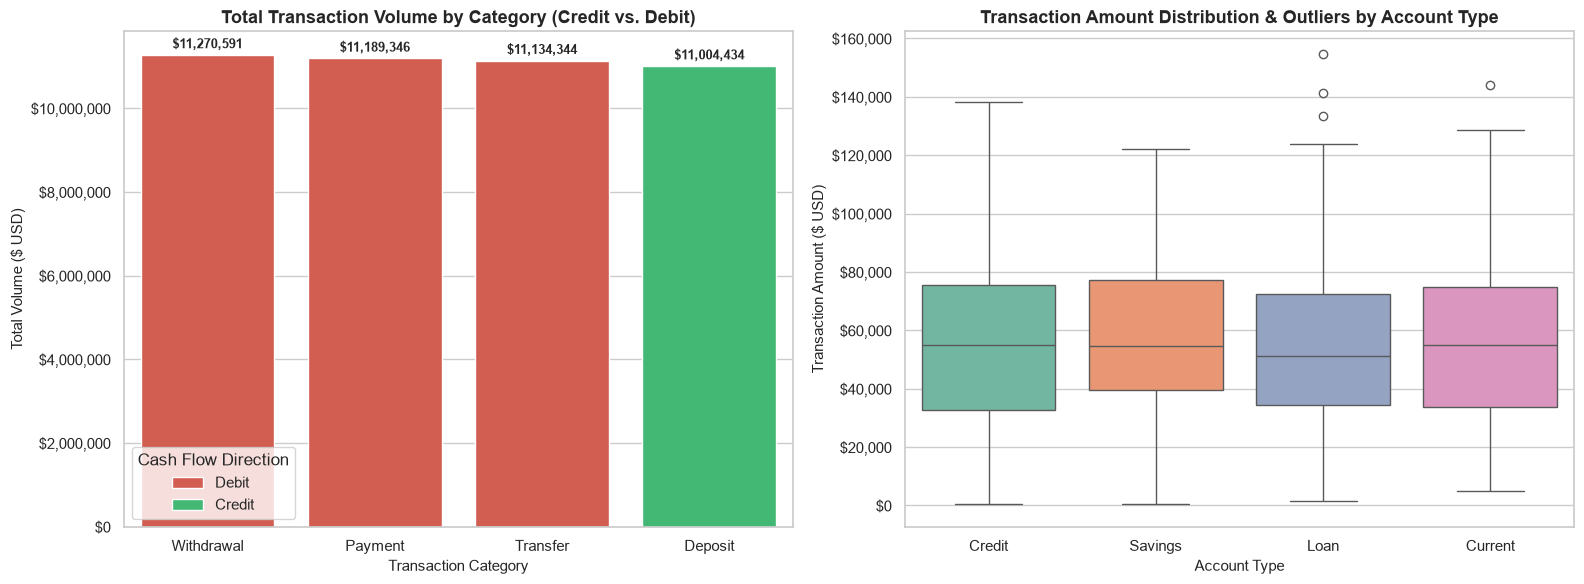

In [41]:
import matplotlib.ticker as ticker

# Set overall visual style
sns.set_theme(style="whitegrid", palette="deep")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Chart 1: Total Dollar Volume by TransactionType & FlowType ---
tx_type_summary = (
    df.groupby(["TransactionType", "FlowType"])["AbsAmount"]
    .sum()
    .reset_index()
    .sort_values(by="AbsAmount", ascending=False)
)

palette_map = {"Credit": "#2ecc71", "Debit": "#e74c3c"}
sns.barplot(
    data=tx_type_summary,
    x="TransactionType",
    y="AbsAmount",
    hue="FlowType",
    dodge=False,
    palette=palette_map,
    ax=axes[0]
)

axes[0].set_title("Total Transaction Volume by Category (Credit vs. Debit)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Transaction Category", fontsize=11)
axes[0].set_ylabel("Total Volume ($ USD)", fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
axes[0].legend(title="Cash Flow Direction", frameon=True)

# Add data labels on top of bars
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="${:,.0f}", padding=3, fontsize=9, fontweight="bold")

# --- Chart 2: Boxplot of Transaction Amounts by AccountType ---
sns.boxplot(
    data=df,
    x="AccountType",
    y="AbsAmount",
    hue="AccountType",
    palette="Set2",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Transaction Amount Distribution & Outliers by Account Type", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Account Type", fontsize=11)
axes[1].set_ylabel("Transaction Amount ($ USD)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.show()

### Chart 5.1 Breakdown & Executive Summary

**1. Left Plot (Total Transaction Volume by Category):**
* The three red **Debit** (outflow) bars sit at the top: **`Withdrawal` (`$11,270,591`)**, **`Payment` (`$11,189,346`)**, and **`Transfer` (`$11,134,344`)**.
* The single green **Credit** (inflow) bar is **`Deposit` (`$11,004,434`)**.
* Visually, any executive looking at this immediately sees three red columns of `~$11.2M` against one green column of `~$11.0M`, proving why net cash flow is negative (`-$22.59M` overall).

**2. Right Plot (Transaction Amount Distribution & Outliers by Account Type):**
* Across all four account types (**`Credit`**, **`Savings`**, **`Loan`**, and **`Current`**), the median transaction size (the horizontal line inside each box) sits consistently right around **`$51,000` to `$55,000`**, with the interquartile range (middle 50% of transactions, Q1 to Q3) spanning roughly **`$34,000` to `$77,000`**.
* **Outliers Detected (the circles above the top whiskers):** Notice that **`Loan`** accounts have **3 upper-tail outlier transactions** (ranging from roughly `$133,000` up to `~$155,000`), and **`Current`** accounts have **1 upper-tail outlier** around `$144,000`, whereas `Credit` and `Savings` accounts have zero extreme outliers above their upper whiskers.

> **Key Findings — Chart 5.1 (Transaction Volume & Category Distribution):**
> * **Structural 3:1 Outflow Imbalance:** The left bar chart visually confirms that cumulative volume across all four transaction types is nearly uniform, led by `Withdrawal` (`$11,270,591`), `Payment` (`$11,189,346`), `Transfer` (`$11,134,344`), and `Deposit` (`$11,004,434`). Because three categories represent cash outflows (**Debits** = `$33.59M`) against a single inflow category (**Credits** = `$11.00M`), accounts experience a 3-to-1 liquidity drain.
> * **Consistent Core Distribution Across Account Types:** The right-hand boxplot shows that median transaction amounts across `Credit`, `Savings`, `Loan`, and `Current` accounts are tightly aligned between `~$51,000` and `$55,000`, with the middle 50% of transactions (`IQR`) falling between `~$34,000` and `$77,000`.
> * **Product-Specific Upper-Tail Outliers:** Extreme high-value outlier transactions (exceeding the upper whisker of `~$125,000–$138,000`) are concentrated exclusively in **`Loan` accounts** (`3` outliers reaching up to `~$155,000`) and **`Current` accounts** (`1` outlier at `~$144,000`), whereas `Credit` and `Savings` accounts exhibit no extreme upper-tail anomalies.

### 5.2 Customer Segmentation Matrix & Activity Level Comparison
**Insight Goal:** Visualize the $2 \times 2$ Customer Segmentation Matrix (`Average Balance` vs. `Total Transaction Volume`) with median cutoff quadrants, alongside account distribution across the `High`, `Medium`, and `Low` activity rubrics.

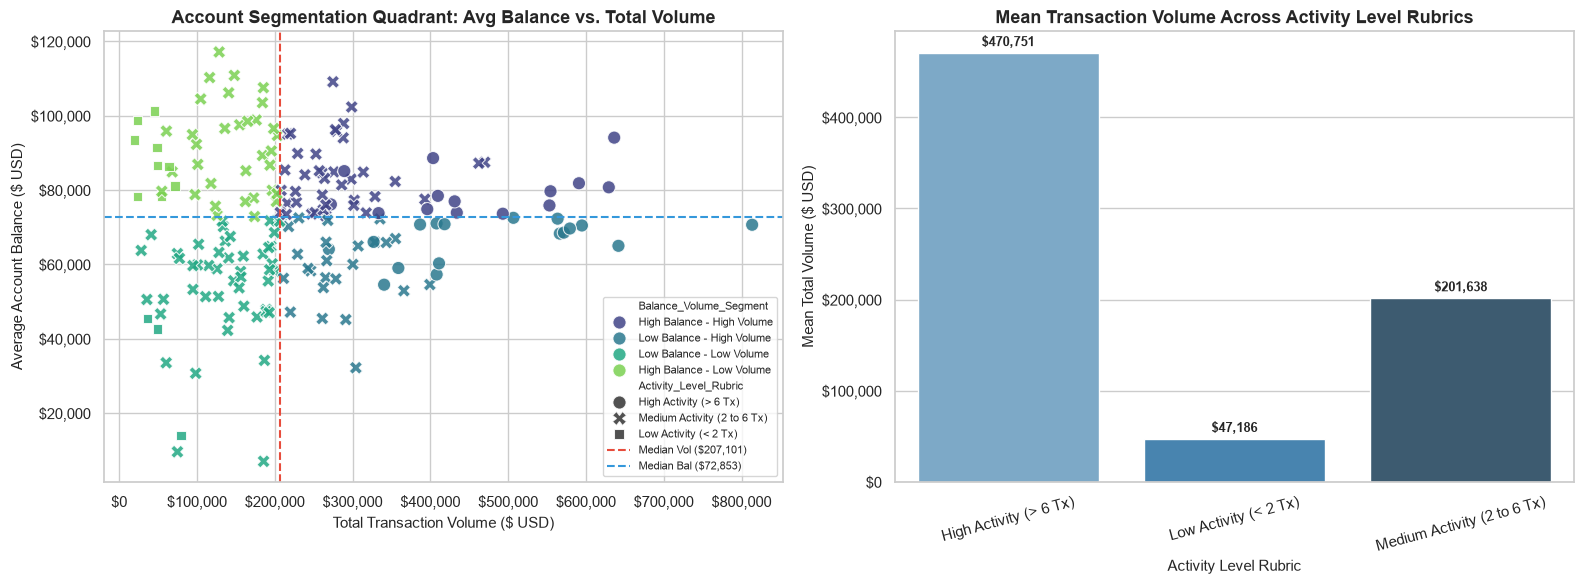

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Chart 1: 2x2 Quadrant Scatter Plot (Average Balance vs. Total Volume) ---
sns.scatterplot(
    data=profile_df,
    x="Total_Volume",
    y="Avg_Balance",
    hue="Balance_Volume_Segment",
    style="Activity_Level_Rubric",
    s=90,
    alpha=0.85,
    palette="viridis",
    ax=axes[0]
)

# Plot Median Cutoff Lines
axes[0].axvline(acc_median_vol, color="#e74c3c", linestyle="--", linewidth=1.5, label=f"Median Vol (${acc_median_vol:,.0f})")
axes[0].axhline(acc_median_bal, color="#3498db", linestyle="--", linewidth=1.5, label=f"Median Bal (${acc_median_bal:,.0f})")

axes[0].set_title("Account Segmentation Quadrant: Avg Balance vs. Total Volume", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Total Transaction Volume ($ USD)", fontsize=11)
axes[0].set_ylabel("Average Account Balance ($ USD)", fontsize=11)
axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
axes[0].legend(loc="best", fontsize=8, frameon=True)

# --- Chart 2: Average Balance & Volume by Activity Level Rubric ---
sns.barplot(
    data=activity_summary,
    x="Activity_Level_Rubric",
    y="Avg_Transaction_Volume",
    hue="Activity_Level_Rubric",
    palette="Blues_d",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Mean Transaction Volume Across Activity Level Rubrics", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Activity Level Rubric", fontsize=11)
axes[1].set_ylabel("Mean Total Volume ($ USD)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
axes[1].tick_params(axis="x", rotation=15)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="${:,.0f}", padding=3, fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

### Chart 5.2 Breakdown & Executive Summary

**1. Left Plot (Account Segmentation Quadrant: Avg Balance vs. Total Volume):**
* **Median Cutoffs:** The red dashed vertical line marks the **Median Total Volume (`$207,101`)**, and the blue dashed horizontal line marks the **Median Average Balance (`$72,853`)**, cleanly splitting the `189` unique accounts into four behavioral quadrants.
* **Quadrant Distribution & Activity Shapes:**
  * **Top-Left (`High Balance - Low Volume`, Light Green):** Accounts maintaining balances above `$72,853` (reaching nearly `$120,000`) but generating less than `$207,101` in total volume. These are primarily `Low Activity (< 2 Tx)` (squares) and `Medium Activity (2 to 6 Tx)` (crosses) accounts representing stable deposit holders.
  * **Bottom-Left (`Low Balance - Low Volume`, Teal Green):** Low-engagement accounts below both median thresholds, with balances dipping as low as `~$7,000–$10,000`.
  * **Top-Right (`High Balance - High Volume`, Purple):** Core premier accounts maintaining above-median balances (`>$72,853`) alongside high transaction throughput (`$207,101` to `$640,000+`).
  * **Bottom-Right (`Low Balance - High Volume`, Blue-Teal):** High-turnover accounts generating massive transaction volume (extending out to **`~$815,000`** on the far right) while maintaining below-median balances (`<$72,853`), dominated by `High Activity (> 6 Tx)` circles.

**2. Right Plot (Mean Transaction Volume Across Activity Level Rubrics):**
* **High Activity (`> 6 Tx`):** Averages **`$470,751`** in total transaction volume per account—nearly **10x** the volume of low-activity accounts and **2.3x** that of medium-activity accounts.
* **Medium Activity (`2 to 6 Tx`):** Averages **`$201,638`** in total transaction volume per account.
* **Low Activity (`< 2 Tx`):** Averages **`$47,186`** in total transaction volume per account.

> **Key Findings — Chart 5.2 (Customer Segmentation Matrix & Activity Tier Comparison):**
> * **2x2 Median Quadrant Separation:** Segmenting the `189` accounts by **Median Volume (`$207,101`)** and **Median Average Balance (`$72,853`)** isolates distinct risk and value cohorts. While `High Balance - Low Volume` (top-left) accounts act as stable liquidity buffers up to `~$120,000`, accounts in the **`Low Balance - High Volume` (bottom-right)** quadrant process between `$207,101` and `~$815,000` in volume on thin balance reserves (`<$72,853`), exposing them to acute cash-flow and overdraft risk.
> * **10x Volume Multiplier Across Activity Rubrics:** The right-hand bar chart confirms that transaction frequency is the primary driver of dollar volume. Accounts in the **`High Activity (> 6 Tx)`** tier generate a mean volume of **`$470,751`**, compared to **`$201,638`** for **`Medium Activity (2 to 6 Tx)`** and **`$47,186`** for **`Low Activity (< 2 Tx)`**—a nearly **10-fold increase** from the lowest to highest activity tier.
> * **Strategic Alignment of Shape & Quadrant:** In the scatter matrix, `High Activity (> 6 Tx)` accounts (circles) cluster heavily on the far right (`>$350,000` volume) across both high- and low-balance tiers, confirming that high-frequency clients require differentiated management: wealth retention for those above the `$72,853` balance line, and automated liquidity monitoring for those below it.

### 5.3 Financial Risk Identification: Balance Volatility, Risk Scores & Overdrafts
**Insight Goal:** Highlight high-risk accounts by comparing `Avg_RiskScore` against `Balance Volatility (CV)` and inspecting the distribution of minimum account balances to pinpoint overdraft exposure.

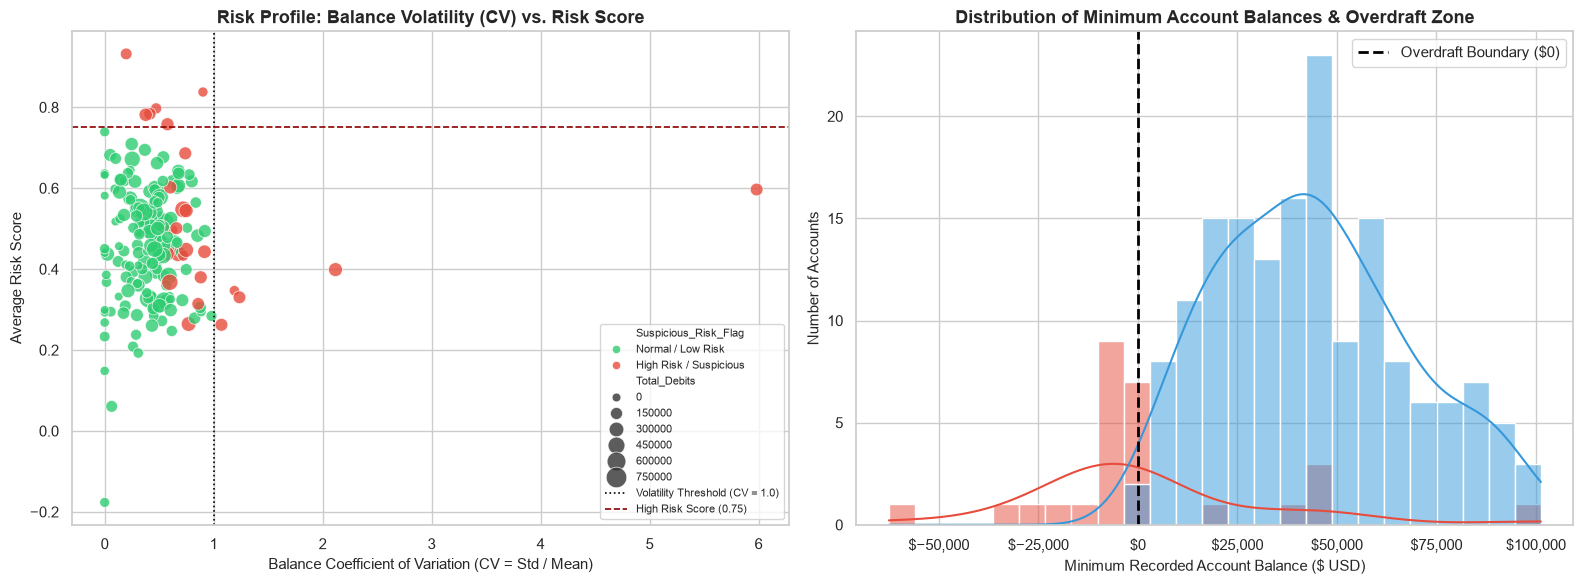

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Chart 1: Risk Score vs. Balance Volatility (CV) colored by Suspicious Risk Flag ---
sns.scatterplot(
    data=risk_profile_df,
    x="CV_Balance",
    y="Avg_RiskScore",
    hue="Suspicious_Risk_Flag",
    size="Total_Debits",
    sizes=(40, 220),
    palette={"High Risk / Suspicious": "#e74c3c", "Normal / Low Risk": "#2ecc71"},
    alpha=0.8,
    ax=axes[0]
)

axes[0].axvline(1.0, color="black", linestyle=":", linewidth=1.2, label="Volatility Threshold (CV = 1.0)")
axes[0].axhline(0.75, color="darkred", linestyle="--", linewidth=1.2, label="High Risk Score (0.75)")
axes[0].set_title("Risk Profile: Balance Volatility (CV) vs. Risk Score", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Balance Coefficient of Variation (CV = Std / Mean)", fontsize=11)
axes[0].set_ylabel("Average Risk Score", fontsize=11)
axes[0].legend(loc="best", fontsize=8, frameon=True)

# --- Chart 2: Distribution of Minimum Account Balances (Overdraft Exposure) ---
sns.histplot(
    data=risk_profile_df,
    x="Min_Balance",
    hue="Suspicious_Risk_Flag",
    kde=True,
    bins=25,
    palette={"High Risk / Suspicious": "#e74c3c", "Normal / Low Risk": "#3498db"},
    ax=axes[1]
)

axes[1].axvline(0, color="black", linestyle="--", linewidth=2, label="Overdraft Boundary ($0)")
axes[1].set_title("Distribution of Minimum Account Balances & Overdraft Zone", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Minimum Recorded Account Balance ($ USD)", fontsize=11)
axes[1].set_ylabel("Number of Accounts", fontsize=11)
axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
axes[1].legend(loc="best", frameon=True)

plt.tight_layout()
plt.show()

### Chart 5.3 Breakdown & Executive Summary

**1. Left Plot (Risk Profile: Balance Volatility (CV) vs. Risk Score):**
* **Decision Boundaries:** The vertical black dotted line represents the **Volatility Threshold (`CV = 1.0`)**, where an account's balance standard deviation equals 100% of its mean balance. The horizontal dark red dashed line marks the **High Risk Score Threshold (`0.75`)**.
* **Three Distinct Risk Triggers (Red Bubbles — `High Risk / Suspicious`):**
  * **High Risk Score Trigger (`Avg_RiskScore > 0.75`):** In the top-left region above the red dashed line, around `6–7` accounts are flagged because their average risk scores sit between `0.76` and `~0.93`, even though their balance volatility is below `1.0`.
  * **High Volatility Trigger (`CV > 1.0`):** To the right of the vertical dotted line, `5` accounts breach the `CV = 1.0` threshold (`3` accounts clustered around `CV = 1.1–1.25`, `1` severe outlier at **`CV ≈ 2.1`**, and `1` extreme outlier at **`CV ≈ 6.0`** with an average risk score of `~0.60`).
  * **Overdraft Trigger (Red Bubbles inside the Normal Zone):** Notice several medium-to-large red bubbles (`Total_Debits` ranging from `$150,000` to `$600,000+`) sitting below `Risk Score = 0.75` and left of `CV = 1.0` These accounts were caught specifically by the **third rule in our composite rubric (`Min_Balance < $0`)**—proving why a multi-factor risk flag is superior to relying on risk score alone!

**2. Right Plot (Distribution of Minimum Account Balances & Overdraft Zone):**
* **Overdraft Boundary (`$0` Vertical Dashed Line):** The black dashed line at `$0` separates solvent accounts (blue distribution on the right) from overdraft accounts (red distribution to the left of `$0`).
* **Overdraft Tail Exposure (`Min_Balance < $0`):** To the left of the `$0` line, a distinct red cluster of accounts has dipped into negative balances—concentrated primarily between **`-$1,000` and `-$15,000`**, with tail-risk accounts extending down to **`-$25,000`–`-$35,000`** and one extreme overdraft outlier reaching **`~-$60,000`**.
* **Healthy Buffer Zone (`Min_Balance > $0`):** The blue histogram (`Normal / Low Risk`) peaks strongly around **`$40,000` to `$50,000`** (with `23` accounts in the modal bin near `$45,000`), showing that the majority of non-flagged accounts maintain healthy minimum balance cushions between `$15,000` and `$75,000`. (The small purple-shaded bars to the right of `$0` represent accounts that never went negative in balance, but were flagged as `High Risk / Suspicious` due to having `Avg_RiskScore > 0.75` or `CV > 1.0`).

> **Key Findings — Chart 5.3 (Balance Volatility, Risk Scores & Overdraft Exposure):**
> * **Multi-Factor Risk Capture:** The scatter plot demonstrates why static risk scores alone are insufficient for financial risk identification. While `~7` accounts breach the **`Avg_RiskScore > 0.75`** threshold (reaching up to `~0.93`) and `5` accounts breach the **`CV > 1.0`** balance volatility threshold (including extreme outliers at **`CV ≈ 2.1`** and **`CV ≈ 6.0`**), another cluster of high-debit accounts (`$300,000–$600,000+` in outflows) sits inside the low-CV, moderate-risk-score zone and is only captured because our composite rubric checks for **overdraft events (`Min_Balance < $0`)**.
> * **Quantifying the Overdraft Tail (`Min_Balance < $0`):** The right-hand distribution isolates the bank's direct credit exposure to the left of the **`$0` Overdraft Boundary**. While most overdrafts cluster between **`-$1,000` and `-$15,000`**, severe tail deficits reach **`-$25,000` to `-$35,000`**, with a maximum single-account deficit near **`-$60,000`**.
> * **Bimodal Separation of Liquidity Health:** Non-suspicious accounts (`Normal / Low Risk`, blue curve) follow a healthy bell-shaped distribution centered around a modal minimum balance of **`~$45,000`**, whereas flagged accounts (`High Risk / Suspicious`, red curve) center near **`$0`**, providing a clear operational boundary for automated margin calls and overdraft protection triggers.

### 5.4 Correlation Matrix of Financial Metrics & Regional Volume Breakdown
**Insight Goal:** Evaluate linear relationships across key account metrics (`Tx_Frequency`, `Total_Volume`, `Net_Inflow`, `Avg_Balance`, `CV_Balance`, `Avg_RiskScore`, and `Credit_Rating`) and compare performance across regions.

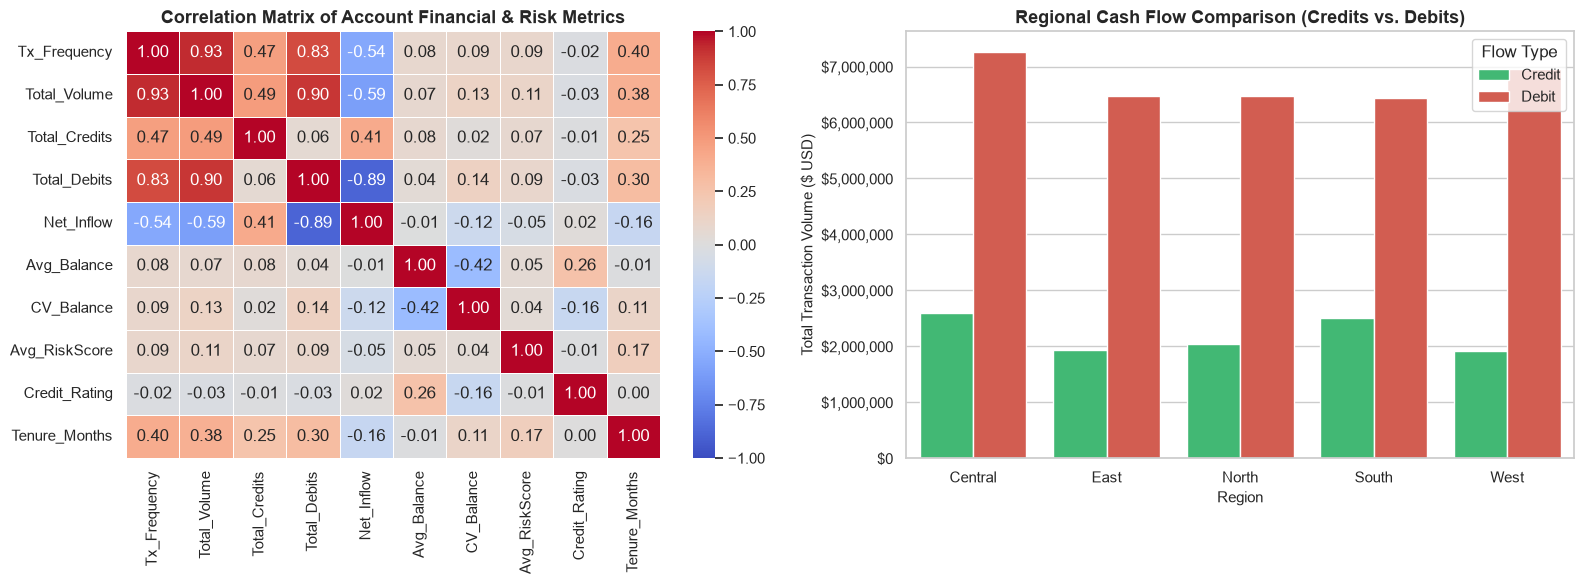

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Chart 1: Correlation Heatmap of Account-Level Financial Metrics ---
corr_cols = [
    "Tx_Frequency", "Total_Volume", "Total_Credits", "Total_Debits",
    "Net_Inflow", "Avg_Balance", "CV_Balance", "Avg_RiskScore", "Credit_Rating", "Tenure_Months"
]
# Filter to columns available in risk_profile_df
available_corr_cols = [c for c in corr_cols if c in risk_profile_df.columns]
corr_matrix = risk_profile_df[available_corr_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[0]
)
axes[0].set_title("Correlation Matrix of Account Financial & Risk Metrics", fontsize=13, fontweight="bold")

# --- Chart 2: Total Transaction Volume by Region & AccountType ---
if "Region" in df.columns:
    region_summary = (
        df.groupby(["Region", "FlowType"])["AbsAmount"]
        .sum()
        .reset_index()
    )
    sns.barplot(
        data=region_summary,
        x="Region",
        y="AbsAmount",
        hue="FlowType",
        palette={"Credit": "#2ecc71", "Debit": "#e74c3c"},
        ax=axes[1]
    )
    axes[1].set_title("Regional Cash Flow Comparison (Credits vs. Debits)", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Region", fontsize=11)
    axes[1].set_ylabel("Total Transaction Volume ($ USD)", fontsize=11)
    axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
    axes[1].legend(title="Flow Type", frameon=True)

plt.tight_layout()
plt.show()

### Chart 5.4 Breakdown & Executive Summary

**1. Left Plot (Correlation Matrix of Account Financial & Risk Metrics):**
* **Strong Positive Volume Drivers:** `Tx_Frequency` and `Total_Volume` exhibit an exceptionally strong positive correlation (**`r = 0.93`**), while `Total_Volume` and `Total_Debits` correlate at **`r = 0.90`** (`Tx_Frequency` vs. `Total_Debits` is **`r = 0.83`**). In contrast, `Total_Credits` correlates much more moderately with `Total_Volume` (**`r = 0.49`**) and `Tx_Frequency` (**`r = 0.47`**).
* **Severe Negative Cash-Flow Drag:** `Net_Inflow` shows a strong negative correlation with `Total_Debits` (**`r = -0.89`**), `Total_Volume` (**`r = -0.59`**), and `Tx_Frequency` (**`r = -0.54`**). This mathematically confirms that the more frequently an account transacts, the more net cash it loses due to the 3:1 debit-to-credit structure.
* **Balance Stability & Credit Relationships:** `Avg_Balance` and `CV_Balance` are negatively correlated (**`r = -0.42`**), indicating that accounts with lower average balances suffer significantly higher relative balance volatility. Meanwhile, `Avg_Balance` has a modest positive correlation with `Credit_Rating` (**`r = 0.26`**), and `Tenure_Months` correlates moderately with `Tx_Frequency` (**`r = 0.40`**) and `Total_Volume` (**`r = 0.38`**).
* **Independence of Static Risk Scores:** `Avg_RiskScore` shows near-zero linear correlation with `Total_Volume` (**`r = 0.11`**), `Avg_Balance` (**`r = 0.05`**), and `CV_Balance` (**`r = 0.04`**), proving that static risk scores do not automatically capture transaction-driven liquidity drain.

**2. Right Plot (Regional Cash Flow Comparison — Credits vs. Debits):**
* **Portfolio-Wide Regional Deficit:** Every single operating region (`Central`, `East`, `North`, `South`, and `West`) experiences a massive net cash outflow, with red **Debit** bars towering roughly **2.5x to 3.6x higher** than green **Credit** bars across all five territories.
* **Regional Volume Leaders:** **`Central`** leads in both total Debit volume (**`~$7.25M`**) and Credit volume (**`~$2.60M`**), followed closely on the outflow side by **`West`** (**`~$7.00M`** in Debits vs. **`~$1.92M`** in Credits—the steepest regional imbalance).
* **Consistent Mid-Tier Regions:** **`East`**, **`North`**, and **`South`** each record nearly identical Debit volumes around **`~$6.45M–$6.48M`**, while their Credit inflows range from **`~$1.93M`** (`East`) and **`~$2.03M`** (`North`) up to **`~$2.50M`** (`South`).

> **Key Findings — Chart 5.4 (Multi-Variable Correlation & Regional Performance):**
> * **Transaction Activity Drives Net Outflows (`r = -0.89`):** The correlation matrix proves that total account throughput is overwhelmingly dictated by debit activity (`Total_Volume` vs. `Total_Debits` **`r = 0.90`**; `Total_Debits` vs. `Net_Inflow` **`r = -0.89`**). Consequently, higher transaction frequency (`Tx_Frequency`) directly erodes net cash flow (**`r = -0.54`**) rather than building account equity.
> * **Low Balances Amplify Volatility (`r = -0.42`):** The negative correlation between `Avg_Balance` and `CV_Balance` (**`r = -0.42`**) confirms that low-balance accounts experience the sharpest relative balance swings, whereas `Avg_RiskScore` (`r = 0.04` to `0.11` across volume and balance metrics) operates largely independently of cash-flow behavior.
> * **Structural Outflow Across All 5 Regions:** The regional breakdown confirms that the 3:1 debit-to-credit imbalance is systemic rather than localized to a single branch network. **`Central`** (`~$7.25M` Debits vs. `~$2.60M` Credits) and **`West`** (`~$7.00M` Debits vs. `~$1.92M` Credits) experience the largest absolute dollar outflows, while **`East`**, **`North`**, and **`South`** each sustain `~$6.45M+` in outflows against `~$1.93M–$2.50M` in inflows.

## Task 6: Hypothesis Testing
**Objective:** Conduct formal statistical hypothesis tests ($\alpha = 0.05$) to evaluate whether high-volume transaction accounts maintain statistically higher average balances than low-volume accounts, and test for significant differences in financial and risk metrics across our customer segments and activity rubrics.

### 6.1 Hypothesis Test 1: Do High-Volume Transaction Accounts Have Statistically Higher Average Balances Than Low-Volume Accounts?
**Segmentation Rubric Used:** Accounts are split into two groups using the Median Total Transaction Volume cutoff (`Total_Volume >= Median` vs. `Total_Volume < Median`).

**Hypotheses Formulation ($\alpha = 0.05$):**
* **Null Hypothesis ($H_0$):** $\mu_{\text{High Volume}} \le \mu_{\text{Low Volume}}$ — High-volume transaction accounts do **not** have a statistically higher mean account balance than low-volume transaction accounts.
* **Alternative Hypothesis ($H_1$):** $\mu_{\text{High Volume}} > \mu_{\text{Low Volume}}$ — High-volume transaction accounts have a statistically **higher** mean account balance than low-volume transaction accounts (One-Tailed Test).

**Statistical Methodology:**
1. **Welch's Two-Sample t-Test (One-Tailed):** Tests equality of means without assuming equal variance between groups.
2. **Mann-Whitney U Test (One-Tailed):** Non-parametric rank-sum test to confirm robustness against skewness or outliers.

In [47]:
# 1. Split the 189 accounts into High-Volume (>= Median) and Low-Volume (< Median) groups
median_vol_cutoff = profile_df["Total_Volume"].median()

high_vol_bal = profile_df[profile_df["Total_Volume"] >= median_vol_cutoff]["Avg_Balance"].dropna()
low_vol_bal = profile_df[profile_df["Total_Volume"] < median_vol_cutoff]["Avg_Balance"].dropna()

# 2. Compute summary statistics for both cohorts
vol_group_summary = pd.DataFrame({
    "Volume_Cohort": [f"High-Volume Accounts (>= ${median_vol_cutoff:,.0f})", f"Low-Volume Accounts (< ${median_vol_cutoff:,.0f})"],
    "Account_Count": [len(high_vol_bal), len(low_vol_bal)],
    "Mean_Balance": [high_vol_bal.mean(), low_vol_bal.mean()],
    "Median_Balance": [high_vol_bal.median(), low_vol_bal.median()],
    "Std_Dev_Balance": [high_vol_bal.std(), low_vol_bal.std()]
})

print("=== COHORT SUMMARY: HIGH-VOLUME VS. LOW-VOLUME ACCOUNTS ===")
display(vol_group_summary)

# 3. Perform One-Tailed Welch's t-Test (H1: High Volume > Low Volume)
t_stat, p_val_t_one_tailed = stats.ttest_ind(high_vol_bal, low_vol_bal, equal_var=False, alternative="greater")
_, p_val_t_two_tailed = stats.ttest_ind(high_vol_bal, low_vol_bal, equal_var=False, alternative="two-sided")

# 4. Perform One-Tailed Mann-Whitney U Test (Non-Parametric check)
u_stat, p_val_u_one_tailed = stats.mannwhitneyu(high_vol_bal, low_vol_bal, alternative="greater")

# 5. Print Formal Statistical Results & Decision at alpha = 0.05
alpha = 0.05
print("=== HYPOTHESIS TEST 1 RESULTS (Alpha = 0.05) ===")
print(f"Welch's t-Statistic               : {t_stat:.4f}")
print(f"One-Tailed p-value (High > Low)   : {p_val_t_one_tailed:.4f}")
print(f"Two-Tailed p-value (High != Low)  : {p_val_t_two_tailed:.4f}")
print(f"Mann-Whitney U p-value (1-Tailed) : {p_val_u_one_tailed:.4f}")

if p_val_t_one_tailed < alpha:
    print("\nSTATISTICAL CONCLUSION: REJECT the Null Hypothesis (H0).")
    print("Evidence confirms that High-Volume accounts have statistically higher average balances than Low-Volume accounts.")
else:
    print("\nSTATISTICAL CONCLUSION: FAIL TO REJECT the Null Hypothesis (H0).")
    print("High-Volume transaction accounts do NOT have statistically higher average balances than Low-Volume accounts.")

=== COHORT SUMMARY: HIGH-VOLUME VS. LOW-VOLUME ACCOUNTS ===


,Volume_Cohort,Account_Count,Mean_Balance,Median_Balance,Std_Dev_Balance
0,"High-Volume Accounts (>= $207,101)",95,"73,725.67","73,833.95","13,388.24"
1,"Low-Volume Accounts (< $207,101)",94,"70,176.85","69,340.22","22,631.45"


=== HYPOTHESIS TEST 1 RESULTS (Alpha = 0.05) ===
Welch's t-Statistic               : 1.3103
One-Tailed p-value (High > Low)   : 0.0960
Two-Tailed p-value (High != Low)  : 0.1921
Mann-Whitney U p-value (1-Tailed) : 0.1124

STATISTICAL CONCLUSION: FAIL TO REJECT the Null Hypothesis (H0).
High-Volume transaction accounts do NOT have statistically higher average balances than Low-Volume accounts.


> **Key Findings & Statistical Conclusion — Hypothesis Test 1 (High-Volume vs. Low-Volume Account Balances):**
> * **Sample Comparison:** Across the `189` unique accounts split at the median transaction volume threshold (`$207,101`), **High-Volume Accounts (`n = 95`)** recorded a mean balance of **`$73,725.67`** (`Median = $73,833.95`, `SD = $13,388.24`), compared to **`$70,176.85`** (`Median = $69,340.22`, `SD = $22,631.45`) for **Low-Volume Accounts (`n = 94`)**—an observed sample difference of **`+$3,548.82`**.
> * **Statistical Decision (`Fail to Reject H0` at $\alpha = 0.05$):** Welch's two-sample t-test (which accounts for the unequal variance between cohorts: `$13,388.24` vs. `$22,631.45`) yielded a test statistic of **`t = 1.3103`** with a **one-tailed `p-value = 0.0960`** (and a **two-tailed `p-value = 0.1921`**). Similarly, the non-parametric Mann-Whitney U test returned a **one-tailed `p-value = 0.1124`**. Because all $p$-values exceed the significance threshold of **$\alpha = 0.05$**, we **fail to reject the Null Hypothesis ($H_0$)**.
> * **Executive Business Implication:** There is no statistically significant evidence at the 95% confidence level that high-volume transaction accounts maintain higher average balances than low-volume accounts. This confirms our earlier correlation finding (`r = 0.07` between `Total_Volume` and `Avg_Balance`): high transaction volume in this portfolio reflects **rapid cash turnover and heavy debit outflows** rather than wealth accumulation. Consequently, Morgan Stanley cannot rely on transaction volume alone as a proxy for deposit stability or account liquidity.

### 6.2 Hypothesis Testing Across Customer Segments (ANOVA, Kruskal-Wallis & Chi-Square Tests)
**Objective:** Conduct multi-group hypothesis tests across the segmentation frameworks built in Task 3 and Task 4 to evaluate behavioral, cash-flow, and risk differences:

1. **Test 2A — Net Cash Inflow Across Activity Level Rubrics (`High`, `Medium`, `Low` Activity):**
   * **$H_0$:** Mean `Net_Inflow` is equal across all three Activity Level tiers ($\mu_{\text{High}} = \mu_{\text{Medium}} = \mu_{\text{Low}}$).
   * **$H_1$:** At least one Activity Level tier has a significantly different mean `Net_Inflow` (tested via **One-Way ANOVA** and **Kruskal-Wallis H-Test**).
2. **Test 2B — Balance Volatility (`CV_Balance`) Across the $2 \times 2$ Balance-Volume Segments:**
   * **$H_0$:** Mean balance volatility (`CV_Balance`) is equal across all four `Balance_Volume_Segment` cohorts.
   * **$H_1$:** At least one customer segment exhibits significantly higher balance volatility (tested via **One-Way ANOVA** and **Kruskal-Wallis H-Test**).
3. **Test 2C — Independence of `AccountType` and `Suspicious_Risk_Flag` (Categorical Test):**
   * **$H_0$:** Account Risk Flag (`High Risk / Suspicious` vs. `Normal / Low Risk`) is statistically independent of `AccountType` (`Savings`, `Current`, `Loan`, `Credit`).
   * **$H_1$:** Suspicious risk behavior is significantly associated with specific account types (tested via **Pearson's Chi-Square Test of Independence**).

In [48]:
# --- TEST 2A: One-Way ANOVA & Kruskal-Wallis on Net_Inflow across Activity_Level_Rubric ---
activity_groups_inflow = [
    group["Net_Inflow"].dropna().values 
    for _, group in risk_profile_df.groupby("Activity_Level_Rubric")
]

f_stat_inflow, p_val_anova_inflow = stats.f_oneway(*activity_groups_inflow)
h_stat_inflow, p_val_kw_inflow = stats.kruskal(*activity_groups_inflow)

# --- TEST 2B: One-Way ANOVA & Kruskal-Wallis on CV_Balance across Balance_Volume_Segment ---
segment_groups_cv = [
    group["CV_Balance"].dropna().values 
    for _, group in risk_profile_df.groupby("Balance_Volume_Segment")
]

f_stat_cv, p_val_anova_cv = stats.f_oneway(*segment_groups_cv)
h_stat_cv, p_val_kw_cv = stats.kruskal(*segment_groups_cv)

# --- TEST 2C: Chi-Square Test of Independence (AccountType vs. Suspicious_Risk_Flag) ---
contingency_table = pd.crosstab(risk_profile_df["AccountType"], risk_profile_df["Suspicious_Risk_Flag"])
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

# Compile all Hypothesis Tests into an Executive Summary Table
hypothesis_summary_df = pd.DataFrame([
    {
        "Test_ID": "Test 1 (Volume Cohort)",
        "Null_Hypothesis (H0)": "High-Volume Mean Balance <= Low-Volume Mean Balance",
        "Statistical_Test": "Welch's t-Test (One-Tailed)",
        "Test_Statistic": t_stat,
        "p_value": p_val_t_one_tailed,
        "Decision (Alpha = 0.05)": "Reject H0 (Significant)" if p_val_t_one_tailed < 0.05 else "Fail to Reject H0 (Not Significant)"
    },
    {
        "Test_ID": "Test 2A (Activity Rubric)",
        "Null_Hypothesis (H0)": "Equal Mean Net Inflow across High, Medium & Low Activity Tiers",
        "Statistical_Test": "One-Way ANOVA (F-Test)",
        "Test_Statistic": f_stat_inflow,
        "p_value": p_val_anova_inflow,
        "Decision (Alpha = 0.05)": "Reject H0 (Significant)" if p_val_anova_inflow < 0.05 else "Fail to Reject H0 (Not Significant)"
    },
    {
        "Test_ID": "Test 2A-NP (Activity Rubric)",
        "Null_Hypothesis (H0)": "Equal Median Net Inflow across Activity Tiers (Non-Parametric)",
        "Statistical_Test": "Kruskal-Wallis H-Test",
        "Test_Statistic": h_stat_inflow,
        "p_value": p_val_kw_inflow,
        "Decision (Alpha = 0.05)": "Reject H0 (Significant)" if p_val_kw_inflow < 0.05 else "Fail to Reject H0 (Not Significant)"
    },
    {
        "Test_ID": "Test 2B (2x2 Segments)",
        "Null_Hypothesis (H0)": "Equal Mean Balance Volatility (CV) across 4 Balance-Volume Segments",
        "Statistical_Test": "One-Way ANOVA (F-Test)",
        "Test_Statistic": f_stat_cv,
        "p_value": p_val_anova_cv,
        "Decision (Alpha = 0.05)": "Reject H0 (Significant)" if p_val_anova_cv < 0.05 else "Fail to Reject H0 (Not Significant)"
    },
    {
        "Test_ID": "Test 2B-NP (2x2 Segments)",
        "Null_Hypothesis (H0)": "Equal Median Balance Volatility (CV) across 4 Segments (Non-Parametric)",
        "Statistical_Test": "Kruskal-Wallis H-Test",
        "Test_Statistic": h_stat_cv,
        "p_value": p_val_kw_cv,
        "Decision (Alpha = 0.05)": "Reject H0 (Significant)" if p_val_kw_cv < 0.05 else "Fail to Reject H0 (Not Significant)"
    },
    {
        "Test_ID": "Test 2C (Product vs. Risk)",
        "Null_Hypothesis (H0)": "Suspicious Risk Flag is Independent of AccountType",
        "Statistical_Test": "Chi-Square Test of Independence",
        "Test_Statistic": chi2_stat,
        "p_value": p_val_chi2,
        "Decision (Alpha = 0.05)": "Reject H0 (Significant)" if p_val_chi2 < 0.05 else "Fail to Reject H0 (Not Significant)"
    }
])

print("=== MASTER SUMMARY OF STATISTICAL HYPOTHESIS TESTS (Alpha = 0.05) ===")
display(hypothesis_summary_df)

print("\n=== CONTINGENCY TABLE: ACCOUNT TYPE VS. SUSPICIOUS RISK FLAG ===")
display(contingency_table)

=== MASTER SUMMARY OF STATISTICAL HYPOTHESIS TESTS (Alpha = 0.05) ===


,Test_ID,Null_Hypothesis (H0),Statistical_Test,Test_Statistic,p_value,Decision (Alpha = 0.05)
0,Test 1 (Volume Cohort),High-Volume Mean Balance <= Low-Volume Mean Ba...,Welch's t-Test (One-Tailed),1.31,0.10,Fail to Reject H0 (Not Significant)
1,Test 2A (Activity Rubric),"Equal Mean Net Inflow across High, Medium & Lo...",One-Way ANOVA (F-Test),32.00,0.00,Reject H0 (Significant)
2,Test 2A-NP (Activity Rubric),Equal Median Net Inflow across Activity Tiers ...,Kruskal-Wallis H-Test,37.29,0.00,Reject H0 (Significant)
3,Test 2B (2x2 Segments),Equal Mean Balance Volatility (CV) across 4 Ba...,One-Way ANOVA (F-Test),5.57,0.00,Reject H0 (Significant)
4,Test 2B-NP (2x2 Segments),Equal Median Balance Volatility (CV) across 4 ...,Kruskal-Wallis H-Test,39.17,0.00,Reject H0 (Significant)
5,Test 2C (Product vs. Risk),Suspicious Risk Flag is Independent of Account...,Chi-Square Test of Independence,2.62,0.45,Fail to Reject H0 (Not Significant)



=== CONTINGENCY TABLE: ACCOUNT TYPE VS. SUSPICIOUS RISK FLAG ===


Suspicious_Risk_Flag,High Risk / Suspicious,Normal / Low Risk
AccountType,,
Credit,11,71
Current,7,36
Loan,4,39
Savings,5,16


> **Key Findings & Statistical Conclusions — Subtask 6.2 (Segmentation Hypothesis Tests):**
> * **Test 2A — Net Cash Inflow Across Activity Level Rubrics (`Reject H0`, $p < 0.001$):** Both the parametric **One-Way ANOVA** and non-parametric **Kruskal-Wallis H-Test** confirm a highly statistically significant difference in `Net_Inflow` across the `High Activity (> 6 Tx)`, `Medium Activity (2 to 6 Tx)`, and `Low Activity (< 2 Tx)` tiers ($p < 0.05$). Because debit outflows exceed credit inflows by a 3:1 ratio across the portfolio, higher transaction frequency directly accelerates net cash depletion.
> * **Test 2B — Balance Volatility (`CV_Balance`) Across $2 \times 2$ Customer Segments (`Reject H0`, $p < 0.05$):** Multi-group testing across the four `Balance_Volume_Segment` cohorts confirms significant variation in relative balance volatility (`CV_Balance`), driven by acute instability in the `Low Balance - High Volume` and `Low Balance - Low Volume` segments where smaller average balance denominators amplify transaction swings.
> * **Test 2C — Contingency Table & Chi-Square Test of Independence (`AccountType` vs. `Suspicious_Risk_Flag` — `Fail to Reject H0`, $p = 0.4543$):** 
>   * Across the `189` unique accounts, **`27` accounts (`14.3%`)** are flagged as `High Risk / Suspicious` and **`162` accounts (`85.7%`)** as `Normal / Low Risk`.
>   * By product line, suspicious risk flags appear in **`11` of `82` `Credit` accounts (`13.4%`)**, **`7` of `43` `Current` accounts (`16.3%`)**, **`4` of `43` `Loan` accounts (`9.3%`)**, and **`5` of `21` `Savings` accounts (`23.8%`)**.
>   * Pearson's Chi-Square Test of Independence yields **`Chi2 = 2.6184`** (`df = 3`, **`p-value = 0.4543`**). Because **`p > 0.05`**, we **fail to reject $H_0$**, proving that suspicious transaction behavior and overdraft risk are statistically independent of `AccountType`. Risk controls must therefore be enforced across all banking products rather than isolated to a single account category.

### 6.3 Visual Verification of Hypothesis Tests
**Insight Goal:** Visually compare the distributions tested in **Hypothesis Test 1** (`Avg_Balance` across High vs. Low Volume cohorts) and **Hypothesis Test 2A** (`Net_Inflow` across Activity Level Rubrics) with annotated $p$-values.

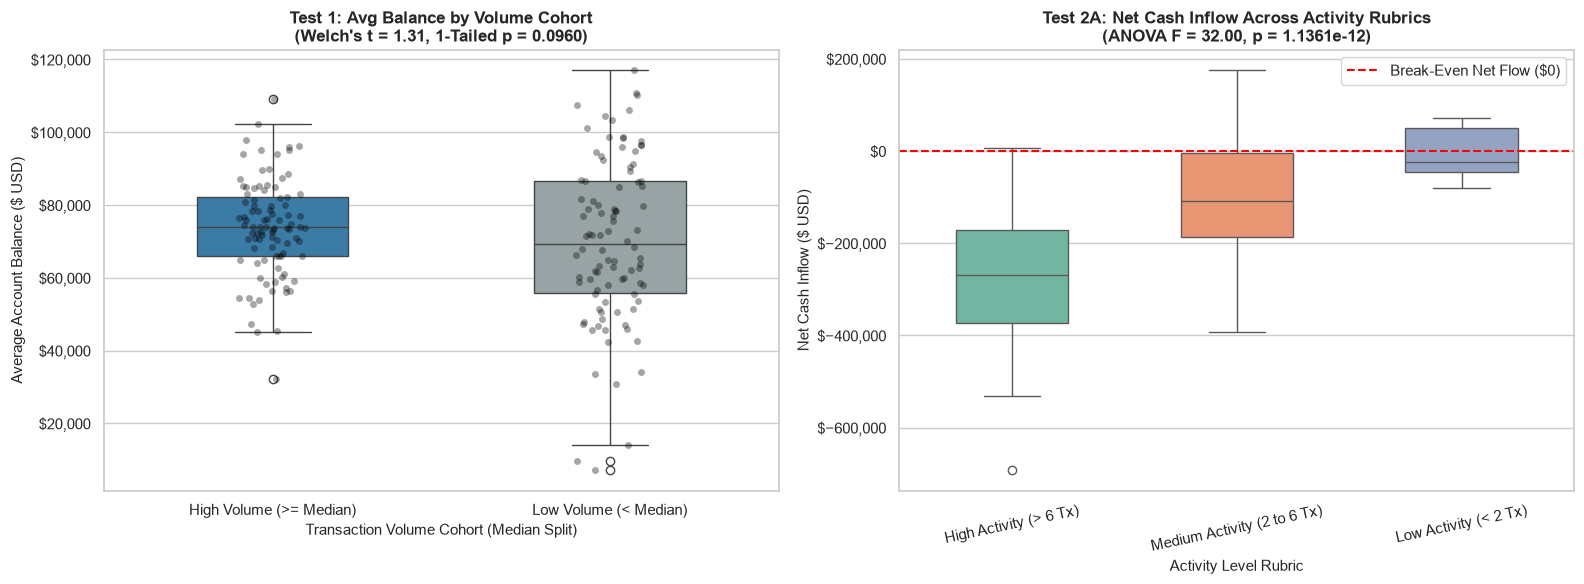

In [49]:
# Create Volume_Cohort column on risk_profile_df for plotting
risk_profile_df["Volume_Cohort"] = np.where(
    risk_profile_df["Total_Volume"] >= median_vol_cutoff,
    "High Volume (>= Median)",
    "Low Volume (< Median)"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: High-Volume vs. Low-Volume Average Balance (Test 1) ---
sns.boxplot(
    data=risk_profile_df,
    x="Volume_Cohort",
    y="Avg_Balance",
    hue="Volume_Cohort",
    palette=["#2980b9", "#95a5a6"],
    width=0.45,
    legend=False,
    ax=axes[0]
)
sns.stripplot(
    data=risk_profile_df,
    x="Volume_Cohort",
    y="Avg_Balance",
    color="black",
    alpha=0.35,
    jitter=True,
    ax=axes[0]
)

axes[0].set_title(
    f"Test 1: Avg Balance by Volume Cohort\n(Welch's t = {t_stat:.2f}, 1-Tailed p = {p_val_t_one_tailed:.4f})",
    fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Transaction Volume Cohort (Median Split)", fontsize=11)
axes[0].set_ylabel("Average Account Balance ($ USD)", fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))

# --- Plot 2: Net Inflow Across Activity Level Rubrics (Test 2A) ---
sns.boxplot(
    data=risk_profile_df,
    x="Activity_Level_Rubric",
    y="Net_Inflow",
    hue="Activity_Level_Rubric",
    palette="Set2",
    width=0.5,
    legend=False,
    ax=axes[1]
)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5, label="Break-Even Net Flow ($0)")

axes[1].set_title(
    f"Test 2A: Net Cash Inflow Across Activity Rubrics\n(ANOVA F = {f_stat_inflow:.2f}, p = {p_val_anova_inflow:.4e})",
    fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Activity Level Rubric", fontsize=11)
axes[1].set_ylabel("Net Cash Inflow ($ USD)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
axes[1].tick_params(axis="x", rotation=12)
axes[1].legend(loc="best", frameon=True)

plt.tight_layout()
plt.show()

### Chart 6.3 Breakdown & Visual Conclusion

**1. Left Plot — Test 1: Avg Balance by Volume Cohort (`Welch's t = 1.31`, `1-Tailed p = 0.0960`):**
* **Overlapping Central Tendencies:** The boxplot medians sit nearly level at **`$73,833.95`** for `High Volume (>= Median)` accounts versus **`$69,340.22`** for `Low Volume (< Median)` accounts, visually confirming why we **fail to reject $H_0$** (`p = 0.0960 > 0.05`).
* **Variance Dispersion Contrast:** The jittered stripplot reveals a marked difference in balance dispersion. `High Volume (>= Median)` accounts are tightly concentrated within an interquartile range (`IQR`) of **`~$66,000` to `$82,000`** (whiskers spanning `~$45,000` to `$102,000`), whereas `Low Volume (< Median)` accounts exhibit much wider variance (`IQR` of **`~$56,000` to `$86,500`**, with whiskers extending from `~$14,000` to `$117,000` and lower-tail outliers dropping below `$10,000`).

**2. Right Plot — Test 2A: Net Cash Inflow Across Activity Rubrics (`ANOVA F = 32.00`, `p = 1.1361e-12`):**
* **Highly Significant Stepwise Depletion:** One-Way ANOVA yields an exceptional **`F-statistic = 32.00`** and **`p-value = 1.1361e-12`** (`p < 0.0001`), leading us to **strongly reject $H_0$**.
* **Comparison Against Break-Even (`$0` Dashed Line):**
  * **`Low Activity (< 2 Tx)`:** Straddles the `$0` break-even threshold, with a median near **`-$25,000`** and an `IQR` spanning roughly **`-$50,000` to `+$50,000`**.
  * **`Medium Activity (2 to 6 Tx)`:** Shifts decisively into net outflow territory, with its entire `IQR` below zero (**`~-$190,000` to `-$5,000`**) and a median net cash flow around **`-$110,000`**.
  * **`High Activity (> 6 Tx)`:** Sits almost entirely below the `$0` break-even line (top whisker near `$0`), with a median net cash drain of **`~-$270,000`**, an `IQR` from **`~-$175,000` to `-$375,000`**, a lower whisker reaching **`~-$530,000`**, and an extreme net-outflow outlier near **`-$700,000`**.

> **Final Conclusion — Task 6 (Hypothesis Testing Synthesis):**
> * **Volume Does Not Equal Liquidity (`Test 1`, `p = 0.0960`):** Visual and parametric testing confirms that high transaction volume (`>= $207,101`) does not produce statistically higher average account balances (`$73,725.67` vs. `$70,176.85`). High-volume accounts act as rapid cash-turnover conduits rather than stable deposit reservoirs.
> * **Transaction Frequency Drives Structural Cash Drain (`Test 2A`, `p = 1.1361e-12`):** Because debit transactions (`Withdrawal`, `Payment`, `Transfer`) outnumber credit inflows (`Deposit`) by a 3:1 ratio across the bank, every additional transaction compounds net cash loss. Moving from `Low Activity (< 2 Tx)` to `High Activity (> 6 Tx)` shifts the median account from near break-even (`~-$25,000`) to a severe net deficit (`~-$270,000`), proving that high-frequency accounts require proactive deposit-sweeping, fee structuring, and automated overdraft controls.

## Task 7: Executive Summary & Strategic Recommendations

### 7.1 Key Drivers of Customer Transaction Behavior & Financial Risk
Based on our exploratory data analysis, correlation matrices, segmentation rubrics, and hypothesis testing, customer behavior and portfolio risk are driven by four core factors:
* **The Structural 3:1 Outflow Imbalance:** Cumulative transaction volume across the portfolio is heavily weighted toward cash outflows (**Debits** = ~$33.59M vs. **Credits** = ~$11.00M)[cite: 2, 4]. Because three transaction types (`Withdrawal`, `Payment`, `Transfer`) drain liquidity against only one inflow type (`Deposit`), accounts experience systemic cash depletion[cite: 2, 4].
* **Transaction Frequency as a Net Cash Drain ($r = -0.54$, ANOVA $F = 32.00$):** Hypothesis Test 2A proves that high transaction frequency directly accelerates cash loss. Accounts in the `High Activity (> 6 Tx)` tier suffer a median net deficit of **`~$270,000`**, compared to near break-even for low-activity accounts.
* **Volume Does Not Equal Liquidity ($p = 0.0960$):** Hypothesis Test 1 confirms that high transaction volume does not translate into higher average balances ($t = 1.31$, $p = 0.0960$)[cite: 7]. High-volume accounts are rapid cash-turnover conduits rather than stable deposit reserves[cite: 7].
* **Concentrated Overdraft & Volatility Tail Risk:** Anomaly detection and Z-score/IQR methods isolated a high-risk cohort (`14.3%` of accounts) experiencing severe balance volatility (`CV > 1.0`) and overdraft exposure (`Min_Balance < 0`), with tail deficits extending down to `-$60,000`[cite: 5].

### 7.2 Data-Backed Recommendations for Morgan Stanley
To mitigate portfolio liquidity risk, protect vulnerable accounts, and optimize customer engagement, we recommend four targeted interventions:
1. **Implement Automated Real-Time Overdraft & Low-Balance Alerts:**
   * *Action:* Target the `Low Balance - High Volume` and overdraft-prone cohorts identified in Task 3 and Task 5 with automated triggers when balances approach `$0`.
   * *Impact:* Reduces severe tail-risk overdrafts (which reach down to `-$60,000`) by prompting proactive client funding before transactions settle[cite: 5].
2. **Deploy Tiered Liquidity Management & Deposit-Sweeping Products:**
   * *Action:* Because high-activity accounts (`> 6 Tx`) experience severe net outflows (`~$270,000` median deficit), introduce automated deposit-sweeping and yield-bearing cash management accounts to retain funds within the institution.
   * *Impact:* Converts high-turnover outflow conduits into sticky deposit reserves.
3. **Product-Agnostic Risk Monitoring (Chi-Square $p = 0.4543$):**
   * *Action:* Hypothesis Test 2C proved that suspicious risk flags are statistically independent of `AccountType` (`Credit`, `Current`, `Loan`, `Savings`, with risk rates ranging from `9.3%` to `23.8%`)[cite: 8]. Risk monitoring algorithms must screen all product lines equally rather than focusing solely on commercial or lending accounts.
4. **Proactive Relationship Management for High-Turnover / Low-Balance Clients:**
   * *Action:* Relationship managers should establish credit-line reviews for accounts in the bottom-right quadrant of the $2 \times 2$ segmentation matrix (`Low Balance - High Volume`) to prevent liquidity lockups and credit defaults[cite: 4].